# Notebook 08 — Comparative Evaluation and Statistical Analysis

This notebook completes the Week 9 comparison of **ClinicalBERT, RoBERTa, DeBERTa and Clinical Longformer** for **depression** and **anxiety**. It uses saved test predictions from each model's `best_model` checkpoint and the threshold selected on validation data; it does not retrain or retune any model.

All result tables and figures are generated **separately for depression and anxiety**. Because Clinical Longformer may have been trained from a larger source dataset, fair paired comparisons use the intersection of test admissions shared by all four models within each task. Full model-specific test-cohort metrics are retained as supplementary results.

Week 9 deliverables produced:

- statistical significance report using patient-clustered paired bootstrap and exact McNemar tests;
- age, sex and comorbidity-load subgroup performance breakdown;
- best-performing model identification for each task;
- systematic benchmark summaries and dashboard-ready PNG/SVG figures.

## 1. Imports and analysis controls

Use `COMPARATIVE_RUN_MODE=smoke` for a quick code check (200 bootstrap replicates). The default full analysis uses 2,000 replicates; increase `FULL_BOOTSTRAP_REPEATS` to 5,000 for the final publication run if time permits.

In [1]:
from pathlib import Path
from itertools import combinations
import json
import os
import platform
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
try:
    from IPython.display import HTML, Markdown, display
except ImportError:
    HTML = Markdown = str
    display = print
from scipy.stats import binomtest
from sklearn.calibration import calibration_curve
from sklearn.metrics import (accuracy_score, average_precision_score, balanced_accuracy_score,
                             brier_score_loss, confusion_matrix, f1_score, log_loss,
                             precision_recall_curve, precision_score, recall_score,
                             roc_auc_score, roc_curve)

SEED = 42
RUN_MODE = os.getenv("COMPARATIVE_RUN_MODE", "full").lower()
FULL_BOOTSTRAP_REPEATS = 2000
BOOTSTRAP_REPEATS = 200 if RUN_MODE == "smoke" else FULL_BOOTSTRAP_REPEATS
CONFIDENCE_LEVEL = 0.95
MIN_SUBGROUP_ADMISSIONS = 100
TASKS = ["depression", "anxiety"]
MODEL_ORDER = ["ClinicalBERT", "RoBERTa", "DeBERTa", "Clinical Longformer"]
PRIMARY_METRIC = "pr_auc"
BOOTSTRAP_METRICS = ["pr_auc", "roc_auc", "f1", "balanced_accuracy"]
MODEL_COLORS = {"ClinicalBERT": "#2F6690", "RoBERTa": "#3A7D44",
                "DeBERTa": "#D17A22", "Clinical Longformer": "#7A5195"}

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 180)
sns.set_theme(style="whitegrid", context="notebook")
print("Python:", platform.python_version())
print("Run mode:", RUN_MODE)
print("Bootstrap repeats:", f"{BOOTSTRAP_REPEATS:,}")
display(HTML("<style>"
             ".output_scroll{height:auto!important;max-height:none!important;overflow-y:visible!important}"
             ".jp-OutputArea-child.jp-mod-scrolled,.jp-OutputArea-output{max-height:none!important;overflow-y:visible!important}"
             "</style>"))

Python: 3.13.9
Run mode: full
Bootstrap repeats: 2,000


## 2. Project, run and output paths

The run names follow Notebooks 04–07. If a Clinical Longformer folder has a different context length or text strategy, edit `LONGFORMER_RUN_NAMES` only. Each task receives its own `tables`, `figures` and `dashboard` folders.

In [2]:
def find_project_root(starting_path):
    starting_path = Path(starting_path).expanduser().resolve()
    for location in [starting_path, *starting_path.parents]:
        if (location / "model_outputs").exists() or (location / "dataset").exists() or (location / ".git").exists():
            return location
    return starting_path

PROJECT_ROOT = find_project_root(Path.cwd())
MODEL_OUTPUT_ROOT = PROJECT_ROOT / "model_outputs"
ANALYSIS_DIR = MODEL_OUTPUT_ROOT / "comparative_evaluation"
TASK_DIRS = {
    task: {kind: ANALYSIS_DIR / task / kind for kind in ["tables", "figures", "dashboard"]}
    for task in TASKS
}
SHARED_DIR = ANALYSIS_DIR / "shared"
for task in TASKS:
    for directory in TASK_DIRS[task].values():
        directory.mkdir(parents=True, exist_ok=True)
SHARED_DIR.mkdir(parents=True, exist_ok=True)

LONGFORMER_RUN_NAMES = {
    "depression": "clinical_longformer_depression_masked_selected_2048_full",
    "anxiety": "clinical_longformer_anxiety_masked_selected_2048_full",
}

def resolve_longformer_directory(task):
    base = MODEL_OUTPUT_ROOT / "clinical_longformer"
    configured = base / LONGFORMER_RUN_NAMES[task]
    if configured.exists():
        return configured
    candidates = sorted(base.glob(f"clinical_longformer_{task}_masked_*_full"))
    if len(candidates) == 1:
        return candidates[0]
    if len(candidates) > 1:
        choices = "\n".join(str(path) for path in candidates)
        raise ValueError(f"Multiple Clinical Longformer runs found for {task}. Set LONGFORMER_RUN_NAMES:\n{choices}")
    return configured

def build_run_directories(task):
    return {
        "ClinicalBERT": MODEL_OUTPUT_ROOT / "clinicalbert" / f"clinicalbert_{task}_masked_selected_full",
        "RoBERTa": MODEL_OUTPUT_ROOT / "roberta" / f"roberta_{task}_masked_selected_full",
        "DeBERTa": MODEL_OUTPUT_ROOT / "deberta" / f"deberta_{task}_masked_selected_full",
        "Clinical Longformer": resolve_longformer_directory(task),
    }

RUN_DIRECTORIES = {task: build_run_directories(task) for task in TASKS}
DATASET_PATHS = {task: PROJECT_ROOT / "dataset" / "model_datasets" / f"{task}_dataset_masked.parquet" for task in TASKS}
DEMOGRAPHIC_PATHS = DATASET_PATHS.copy()
for task in TASKS:
    display(Markdown(f"### {task.title()} model runs"))
    display(pd.DataFrame([{"model": model, "run_directory": str(path)}
                          for model, path in RUN_DIRECTORIES[task].items()]))
print("Project root:", PROJECT_ROOT)

### Depression model runs

,model,run_directory
0,ClinicalBERT,/Users/purnaperamune/Documents/GitHub/P000464S...
1,RoBERTa,/Users/purnaperamune/Documents/GitHub/P000464S...
2,DeBERTa,/Users/purnaperamune/Documents/GitHub/P000464S...
3,Clinical Longformer,/Users/purnaperamune/Documents/GitHub/P000464S...


### Anxiety model runs

,model,run_directory
0,ClinicalBERT,/Users/purnaperamune/Documents/GitHub/P000464S...
1,RoBERTa,/Users/purnaperamune/Documents/GitHub/P000464S...
2,DeBERTa,/Users/purnaperamune/Documents/GitHub/P000464S...
3,Clinical Longformer,/Users/purnaperamune/Documents/GitHub/P000464S...


Project root: /Users/purnaperamune/Documents/GitHub/P000464SE-Modern-Transformer-Models-for-Depression-Anxiety-Detection


## 3. Load and validate saved model outputs

Required inputs for every model are `predictions/test_predictions.csv`; manifests, metrics, histories and token summaries are loaded when available. Validation rejects duplicate admissions, non-binary labels, invalid probabilities and missing required columns.

In [3]:
REQUIRED_PREDICTION_COLUMNS = {"subject_id", "hadm_id", "label", "positive_probability", "predicted_label"}

def read_json(path, required=False):
    if not path.exists():
        if required:
            raise FileNotFoundError(path)
        return {}
    with open(path, "r", encoding="utf-8") as input_file:
        return json.load(input_file)

def read_csv_if_present(path):
    return pd.read_csv(path) if path.exists() else pd.DataFrame()

def load_run_artifacts(task, model, run_directory):
    prediction_path = run_directory / "predictions" / "test_predictions.csv"
    if not prediction_path.exists():
        raise FileNotFoundError(f"Missing {task} / {model} predictions: {prediction_path}")
    predictions = pd.read_csv(prediction_path)
    missing = REQUIRED_PREDICTION_COLUMNS.difference(predictions.columns)
    if missing:
        raise ValueError(f"{task} / {model} prediction columns missing: {sorted(missing)}")
    predictions = predictions.copy()
    for column in ["subject_id", "hadm_id"]:
        predictions[column] = pd.to_numeric(predictions[column], errors="raise").astype("int64")
    for column in ["label", "predicted_label"]:
        predictions[column] = pd.to_numeric(predictions[column], errors="raise").astype(int)
    predictions["positive_probability"] = pd.to_numeric(predictions["positive_probability"], errors="raise")
    if predictions["hadm_id"].duplicated().any():
        raise ValueError(f"Duplicate hadm_id values in {task} / {model} predictions.")
    if not predictions[["label", "predicted_label"]].isin([0, 1]).all().all():
        raise ValueError(f"Non-binary labels in {task} / {model} predictions.")
    if predictions["positive_probability"].isna().any() or not predictions["positive_probability"].between(0, 1).all():
        raise ValueError(f"Invalid probabilities in {task} / {model} predictions.")
    return {
        "predictions": predictions.sort_values("hadm_id").reset_index(drop=True),
        "manifest": read_json(run_directory / "run_manifest.json"),
        "saved_metrics": read_json(run_directory / "metrics.json"),
        "history": read_csv_if_present(run_directory / "training_history.csv"),
        "token_summary": read_csv_if_present(run_directory / "token_length_summary.csv"),
        "run_directory": run_directory,
    }

missing_rows = []
for task in TASKS:
    for model in MODEL_ORDER:
        path = RUN_DIRECTORIES[task][model] / "predictions" / "test_predictions.csv"
        if not path.exists():
            missing_rows.append({"model": model, "expected_path": str(path)})
    if missing_rows:
        display(Markdown(f"### Missing files: {task.title()}"))
        display(pd.DataFrame(missing_rows))
        missing_rows = []

all_missing = [(task, model) for task in TASKS for model in MODEL_ORDER
               if not (RUN_DIRECTORIES[task][model] / "predictions" / "test_predictions.csv").exists()]
if all_missing:
    raise FileNotFoundError("One or more test-prediction files are missing. Correct Section 2 paths.")

artifacts = {task: {model: load_run_artifacts(task, model, RUN_DIRECTORIES[task][model])
                    for model in MODEL_ORDER} for task in TASKS}
print("All prediction and run files loaded successfully.")

All prediction and run files loaded successfully.


## 4. Create fair task-specific comparison cohorts

The source cohorts are allowed to differ between Clinical Longformer and the 512-token models. Within each task, the primary comparison uses only admissions shared by all four models. Subject IDs and labels must agree on that intersection. The audit quantifies how many admissions each model contributes and how many are excluded from paired analysis.

In [4]:
def build_common_task_cohort(task):
    admission_sets = {model: set(artifacts[task][model]["predictions"]["hadm_id"]) for model in MODEL_ORDER}
    common_ids = sorted(set.intersection(*admission_sets.values()))
    if not common_ids:
        raise ValueError(f"No shared test admissions were found for {task}.")
    frames = {}
    reference = None
    audit_rows = []
    for model in MODEL_ORDER:
        original = artifacts[task][model]["predictions"]
        frame = original.set_index("hadm_id").loc[common_ids].reset_index()
        frame = frame.sort_values("hadm_id").reset_index(drop=True)
        if reference is None:
            reference = frame[["subject_id", "hadm_id", "label"]].copy()
        elif not frame[["subject_id", "hadm_id", "label"]].equals(reference):
            raise ValueError(f"Subject IDs or labels disagree on the {task} common cohort for {model}.")
        frames[model] = frame
        excluded = len(original) - len(frame)
        audit_rows.append({"model": model, "original_admissions": len(original),
                           "original_patients": original["subject_id"].nunique(),
                           "common_admissions": len(frame), "common_patients": frame["subject_id"].nunique(),
                           "excluded_admissions": excluded,
                           "excluded_percentage": 100 * excluded / len(original) if len(original) else np.nan})
    return frames, pd.DataFrame(audit_rows)

common_frames_by_task = {}
cohort_audit_by_task = {}
for task in TASKS:
    common_frames_by_task[task], cohort_audit_by_task[task] = build_common_task_cohort(task)
    cohort_audit_by_task[task].to_csv(TASK_DIRS[task]["tables"] / "cohort_alignment_audit.csv", index=False)
    display(Markdown(f"### {task.title()} cohort audit"))
    display(cohort_audit_by_task[task].round(2))

### Depression cohort audit

,model,original_admissions,original_patients,common_admissions,common_patients,excluded_admissions,excluded_percentage
0,ClinicalBERT,26782,11561,26782,11561,0,0.0
1,RoBERTa,26782,11561,26782,11561,0,0.0
2,DeBERTa,26782,11561,26782,11561,0,0.0
3,Clinical Longformer,26782,11561,26782,11561,0,0.0


### Anxiety cohort audit

,model,original_admissions,original_patients,common_admissions,common_patients,excluded_admissions,excluded_percentage
0,ClinicalBERT,24991,11215,24991,11215,0,0.0
1,RoBERTa,24991,11215,24991,11215,0,0.0
2,DeBERTa,24991,11215,24991,11215,0,0.0
3,Clinical Longformer,24991,11215,24991,11215,0,0.0


## 5. Overall evaluation tables

PR-AUC is the primary metric because both tasks are imbalanced. The **common-cohort table** is the primary fair comparison. The **full-cohort table** is supplementary and must not be used for paired significance tests when admission sets differ.

In [5]:
def safe_auc(metric_function, labels, probabilities):
    return float(metric_function(labels, probabilities)) if np.unique(labels).size == 2 else np.nan

def calculate_metrics(frame):
    labels = frame["label"].to_numpy(dtype=int)
    predictions = frame["predicted_label"].to_numpy(dtype=int)
    probabilities = frame["positive_probability"].to_numpy(dtype=float)
    tn, fp, fn, tp = confusion_matrix(labels, predictions, labels=[0, 1]).ravel()
    clipped = np.clip(probabilities, 1e-7, 1 - 1e-7)
    return {
        "accuracy": accuracy_score(labels, predictions),
        "balanced_accuracy": balanced_accuracy_score(labels, predictions),
        "precision": precision_score(labels, predictions, zero_division=0),
        "recall": recall_score(labels, predictions, zero_division=0),
        "specificity": tn / (tn + fp) if tn + fp else np.nan,
        "npv": tn / (tn + fn) if tn + fn else np.nan,
        "f1": f1_score(labels, predictions, zero_division=0),
        "roc_auc": safe_auc(roc_auc_score, labels, probabilities),
        "pr_auc": safe_auc(average_precision_score, labels, probabilities),
        "brier_score": brier_score_loss(labels, probabilities),
        "log_loss": log_loss(labels, clipped, labels=[0, 1]),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }

def nested_get(mapping, keys, default=np.nan):
    value = mapping
    for key in keys:
        if not isinstance(value, dict) or key not in value:
            return default
        value = value[key]
    return value

def evaluation_frame(task, frame_source):
    rows = []
    for model in MODEL_ORDER:
        item = artifacts[task][model]
        frame = frame_source[model]
        row = {"model": model, "admissions": len(frame), "patients": frame["subject_id"].nunique(),
               "prevalence": frame["label"].mean(), **calculate_metrics(frame)}
        row.update({
            "threshold": nested_get(item["saved_metrics"], ["test", "threshold"],
                                    item["manifest"].get("selected_validation_threshold", np.nan)),
            "best_validation_epoch": item["manifest"].get("best_epoch", np.nan),
            "best_validation_pr_auc": item["manifest"].get("best_validation_pr_auc", np.nan),
            "training_hours": item["manifest"].get("total_training_seconds", np.nan) / 3600,
        })
        rows.append(row)
    columns = ["model", "admissions", "patients", "prevalence", "threshold", "best_validation_epoch",
               "best_validation_pr_auc", "accuracy", "balanced_accuracy", "precision", "recall",
               "specificity", "npv", "f1", "roc_auc", "pr_auc", "brier_score", "log_loss",
               "training_hours", "tn", "fp", "fn", "tp"]
    return pd.DataFrame(rows)[columns]

common_evaluation_by_task = {}
full_evaluation_by_task = {}
for task in TASKS:
    common_evaluation_by_task[task] = evaluation_frame(task, common_frames_by_task[task])
    full_source = {model: artifacts[task][model]["predictions"] for model in MODEL_ORDER}
    full_evaluation_by_task[task] = evaluation_frame(task, full_source)
    common_evaluation_by_task[task].to_csv(TASK_DIRS[task]["tables"] / "common_cohort_test_evaluation.csv", index=False)
    full_evaluation_by_task[task].to_csv(TASK_DIRS[task]["tables"] / "full_cohort_test_evaluation_supplementary.csv", index=False)
    display(Markdown(f"### {task.title()} — primary common-cohort evaluation"))
    display(common_evaluation_by_task[task].round(4))
    display(Markdown(f"### {task.title()} — supplementary full-cohort evaluation"))
    display(full_evaluation_by_task[task].round(4))

### Depression — primary common-cohort evaluation

,model,admissions,patients,prevalence,threshold,best_validation_epoch,best_validation_pr_auc,accuracy,balanced_accuracy,precision,recall,specificity,npv,f1,roc_auc,pr_auc,brier_score,log_loss,training_hours,tn,fp,fn,tp
0,ClinicalBERT,26782,11561,0.1721,0.6042,2,0.7114,0.8887,0.8204,0.6635,0.7164,0.9245,0.9401,0.6889,0.8935,0.6960,0.1012,0.3641,8.3819,20498,1675,1307,3302
1,RoBERTa,26782,11561,0.1721,0.6614,5,0.7007,0.8888,0.8089,0.6736,0.6869,0.9308,0.9347,0.6802,0.8869,0.6904,0.0964,0.3409,8.7664,20639,1534,1443,3166
2,DeBERTa,26782,11561,0.1721,0.6366,4,0.7345,0.8853,0.8372,0.6396,0.7639,0.9105,0.9489,0.6963,0.9134,0.7315,0.0938,0.3158,18.6491,20189,1984,1088,3521
3,Clinical Longformer,26782,11561,0.1721,0.2200,4,0.7863,0.8958,0.8648,0.6591,0.8175,0.9121,0.9601,0.7298,0.9362,0.7852,0.0689,0.2372,146.6442,20224,1949,841,3768


### Depression — supplementary full-cohort evaluation

,model,admissions,patients,prevalence,threshold,best_validation_epoch,best_validation_pr_auc,accuracy,balanced_accuracy,precision,recall,specificity,npv,f1,roc_auc,pr_auc,brier_score,log_loss,training_hours,tn,fp,fn,tp
0,ClinicalBERT,26782,11561,0.1721,0.6042,2,0.7114,0.8887,0.8204,0.6635,0.7164,0.9245,0.9401,0.6889,0.8935,0.6960,0.1012,0.3641,8.3819,20498,1675,1307,3302
1,RoBERTa,26782,11561,0.1721,0.6614,5,0.7007,0.8888,0.8089,0.6736,0.6869,0.9308,0.9347,0.6802,0.8869,0.6904,0.0964,0.3409,8.7664,20639,1534,1443,3166
2,DeBERTa,26782,11561,0.1721,0.6366,4,0.7345,0.8853,0.8372,0.6396,0.7639,0.9105,0.9489,0.6963,0.9134,0.7315,0.0938,0.3158,18.6491,20189,1984,1088,3521
3,Clinical Longformer,26782,11561,0.1721,0.2200,4,0.7863,0.8958,0.8648,0.6591,0.8175,0.9121,0.9601,0.7298,0.9362,0.7852,0.0689,0.2372,146.6442,20224,1949,841,3768


### Anxiety — primary common-cohort evaluation

,model,admissions,patients,prevalence,threshold,best_validation_epoch,best_validation_pr_auc,accuracy,balanced_accuracy,precision,recall,specificity,npv,f1,roc_auc,pr_auc,brier_score,log_loss,training_hours,tn,fp,fn,tp
0,ClinicalBERT,24991,11215,0.1128,0.8297,3,0.6195,0.9057,0.7725,0.5791,0.6004,0.9445,0.9490,0.5895,0.8813,0.6106,0.0875,0.3163,7.8016,20943,1230,1126,1692
1,RoBERTa,24991,11215,0.1128,0.4322,5,0.6082,0.9024,0.7695,0.5632,0.5979,0.9411,0.9485,0.5800,0.8614,0.5900,0.0804,0.2922,8.1280,20866,1307,1133,1685
2,DeBERTa,24991,11215,0.1128,0.6896,3,0.6471,0.9073,0.7966,0.5787,0.6537,0.9395,0.9552,0.6139,0.8843,0.6400,0.0832,0.2948,17.3210,20832,1341,976,1842
3,Clinical Longformer,24991,11215,0.1128,0.6896,3,0.6471,0.9073,0.7966,0.5787,0.6537,0.9395,0.9552,0.6139,0.8843,0.6400,0.0832,0.2948,17.3210,20832,1341,976,1842


### Anxiety — supplementary full-cohort evaluation

,model,admissions,patients,prevalence,threshold,best_validation_epoch,best_validation_pr_auc,accuracy,balanced_accuracy,precision,recall,specificity,npv,f1,roc_auc,pr_auc,brier_score,log_loss,training_hours,tn,fp,fn,tp
0,ClinicalBERT,24991,11215,0.1128,0.8297,3,0.6195,0.9057,0.7725,0.5791,0.6004,0.9445,0.9490,0.5895,0.8813,0.6106,0.0875,0.3163,7.8016,20943,1230,1126,1692
1,RoBERTa,24991,11215,0.1128,0.4322,5,0.6082,0.9024,0.7695,0.5632,0.5979,0.9411,0.9485,0.5800,0.8614,0.5900,0.0804,0.2922,8.1280,20866,1307,1133,1685
2,DeBERTa,24991,11215,0.1128,0.6896,3,0.6471,0.9073,0.7966,0.5787,0.6537,0.9395,0.9552,0.6139,0.8843,0.6400,0.0832,0.2948,17.3210,20832,1341,976,1842
3,Clinical Longformer,24991,11215,0.1128,0.6896,3,0.6471,0.9073,0.7966,0.5787,0.6537,0.9395,0.9552,0.6139,0.8843,0.6400,0.0832,0.2948,17.3210,20832,1341,976,1842


## 6. Model settings, training history and truncation

These tables document comparability and resource use. They are exported separately by task.

In [6]:
def final_epoch_summary(history):
    if history.empty or "epoch" not in history:
        return {"last_epoch": np.nan, "last_validation_accuracy": np.nan, "last_validation_pr_auc": np.nan}
    row = history.sort_values("epoch").iloc[-1]
    return {"last_epoch": row.get("epoch", np.nan),
            "last_validation_accuracy": row.get("validation_accuracy", np.nan),
            "last_validation_pr_auc": row.get("validation_pr_auc", np.nan)}

settings_by_task = {}
history_by_task = {}
truncation_by_task = {}
for task in TASKS:
    settings_rows, history_rows, token_rows = [], [], []
    for model in MODEL_ORDER:
        item = artifacts[task][model]
        manifest = item["manifest"]
        settings_rows.append({
            "model": model, "pretrained_model": manifest.get("model_name"),
            "optimizer": manifest.get("optimizer", "AdamW"),
            "scheduler": manifest.get("scheduler", "linear warmup and decay"),
            "loss_function": manifest.get("loss_function", "class-weighted cross-entropy"),
            "trainable_layers": manifest.get("trainable_layers", "all encoder layers and classification head"),
            "text_column": manifest.get("text_column"), "maximum_length": manifest.get("maximum_length"),
            "attention_window": manifest.get("attention_window", np.nan),
            "global_attention_policy": manifest.get("global_attention_policy", "not applicable"),
            "learning_rate": manifest.get("learning_rate"), "weight_decay": manifest.get("weight_decay"),
            "warmup_proportion": manifest.get("warmup_proportion"),
            "maximum_gradient_norm": manifest.get("maximum_gradient_norm"),
            "training_batch_size": manifest.get("training_batch_size"),
            "gradient_accumulation_steps": manifest.get("gradient_accumulation_steps"),
            "effective_batch_size": manifest.get("effective_batch_size"),
            "evaluation_batch_size": manifest.get("evaluation_batch_size"),
            "epochs_requested": manifest.get("epochs_requested"),
            "last_completed_epoch": manifest.get("last_completed_epoch"),
            "mixed_precision": manifest.get("mixed_precision"),
            "gradient_checkpointing": manifest.get("gradient_checkpointing", False),
            "seed": manifest.get("seed"), "fine_tuning_verified": manifest.get("fine_tuning_verified"),
        })
        history_rows.append({"model": model, **final_epoch_summary(item["history"])})
        token_summary = item["token_summary"].copy()
        if not token_summary.empty:
            token_summary.insert(0, "model", model)
            token_rows.append(token_summary)
    settings_by_task[task] = pd.DataFrame(settings_rows)
    history_by_task[task] = pd.DataFrame(history_rows)
    truncation_by_task[task] = pd.concat(token_rows, ignore_index=True) if token_rows else pd.DataFrame()
    settings_by_task[task].to_csv(TASK_DIRS[task]["tables"] / "model_settings.csv", index=False)
    history_by_task[task].to_csv(TASK_DIRS[task]["tables"] / "final_epoch_validation_summary.csv", index=False)
    truncation_by_task[task].to_csv(TASK_DIRS[task]["tables"] / "token_truncation_summary.csv", index=False)
    display(Markdown(f"### {task.title()} model settings"))
    display(settings_by_task[task])
    display(Markdown(f"### {task.title()} final completed epoch"))
    display(history_by_task[task].round(4))
    display(Markdown(f"### {task.title()} truncation summary"))
    display(truncation_by_task[task].round(3) if not truncation_by_task[task].empty else Markdown("No token summary found."))

### Depression model settings

,model,pretrained_model,optimizer,scheduler,loss_function,trainable_layers,text_column,maximum_length,attention_window,global_attention_policy,learning_rate,weight_decay,warmup_proportion,maximum_gradient_norm,training_batch_size,gradient_accumulation_steps,effective_batch_size,evaluation_batch_size,epochs_requested,last_completed_epoch,mixed_precision,gradient_checkpointing,seed,fine_tuning_verified
0,ClinicalBERT,emilyalsentzer/Bio_ClinicalBERT,AdamW,linear warmup and decay,class-weighted cross-entropy,all encoder layers and classification head,text_selected,512,NaN,not applicable,0.00002,0.01,NaN,NaN,8,2,NaN,16,8,8,None,False,42,True
1,RoBERTa,FacebookAI/roberta-base,AdamW,linear warmup and decay,class-weighted cross-entropy,all encoder layers and classification head,text_selected,512,NaN,not applicable,0.00002,0.01,NaN,NaN,8,2,NaN,16,8,8,None,False,42,True
2,DeBERTa,microsoft/deberta-v3-base,AdamW,linear warmup and decay,class-weighted cross-entropy,all encoder layers and classification head,text_selected,512,NaN,not applicable,0.00002,0.01,NaN,NaN,8,2,NaN,16,8,8,None,False,42,True
3,Clinical Longformer,yikuan8/Clinical-Longformer,AdamW,linear warmup and decay,class-weighted cross-entropy,all encoder layers and classification head,text_selected,2048,512.0,first_token,0.00002,0.01,0.1,1.0,1,16,16.0,2,8,8,True,True,42,True


### Depression final completed epoch

,model,last_epoch,last_validation_accuracy,last_validation_pr_auc
0,ClinicalBERT,8.0,0.8764,0.6892
1,RoBERTa,8.0,0.8806,0.6798
2,DeBERTa,8.0,0.8811,0.6940
3,Clinical Longformer,8.0,0.9001,0.7553


### Depression truncation summary

...

,model,pretrained_model,optimizer,scheduler,loss_function,trainable_layers,text_column,maximum_length,attention_window,global_attention_policy,learning_rate,weight_decay,warmup_proportion,maximum_gradient_norm,training_batch_size,gradient_accumulation_steps,effective_batch_size,evaluation_batch_size,epochs_requested,last_completed_epoch,mixed_precision,gradient_checkpointing,seed,fine_tuning_verified
0,ClinicalBERT,emilyalsentzer/Bio_ClinicalBERT,AdamW,linear warmup and decay,class-weighted cross-entropy,all encoder layers and classification head,text_selected,512,NaN,not applicable,0.00002,0.01,None,None,8,2,None,16,8,8,None,False,42,True
1,RoBERTa,FacebookAI/roberta-base,AdamW,linear warmup and decay,class-weighted cross-entropy,all encoder layers and classification head,text_selected,512,NaN,not applicable,0.00002,0.01,None,None,8,2,None,16,8,8,None,False,42,True
2,DeBERTa,microsoft/deberta-v3-base,AdamW,linear warmup and decay,class-weighted cross-entropy,all encoder layers and classification head,text_selected,512,NaN,not applicable,0.00002,0.01,None,None,8,2,None,16,8,8,None,False,42,True
3,Clinical Longformer,microsoft/deberta-v3-base,AdamW,linear warmup and decay,class-weighted cross-entropy,all encoder layers and classification head,text_selected,512,NaN,not applicable,0.00002,0.01,None,None,8,2,None,16,8,8,None,False,42,True


### Anxiety final completed epoch

,model,last_epoch,last_validation_accuracy,last_validation_pr_auc
0,ClinicalBERT,8.0,0.9047,0.5738
1,RoBERTa,8.0,0.9056,0.5840
2,DeBERTa,8.0,0.9070,0.6091
3,Clinical Longformer,8.0,0.9070,0.6091


### Anxiety truncation summary

,model,split,admissions,median_tokens,p95_tokens,maximum_tokens,notes_over_512,truncation_percentage
0,ClinicalBERT,train,117524,994.0,2161.0,6439,104458,88.88
1,ClinicalBERT,validation,25548,1003.0,2152.0,5890,22829,89.36
2,ClinicalBERT,test,24991,1000.0,2167.0,6626,22180,88.75
3,RoBERTa,train,117524,1076.0,2327.0,6943,107194,91.21
4,RoBERTa,validation,25548,1087.0,2321.0,6368,23420,91.67
5,RoBERTa,test,24991,1083.0,2328.5,6977,22779,91.15
6,DeBERTa,train,117524,841.0,1825.0,5434,96903,82.45
7,DeBERTa,validation,25548,850.0,1818.0,5050,21198,82.97
8,DeBERTa,test,24991,847.0,1831.0,5623,20555,82.25
9,Clinical Longformer,train,117524,841.0,1825.0,5434,96903,82.45


## 7. Dashboard-ready overall visualizations

Every figure is saved as both high-resolution PNG and scalable SVG. Depression and anxiety are never placed in the same figure.

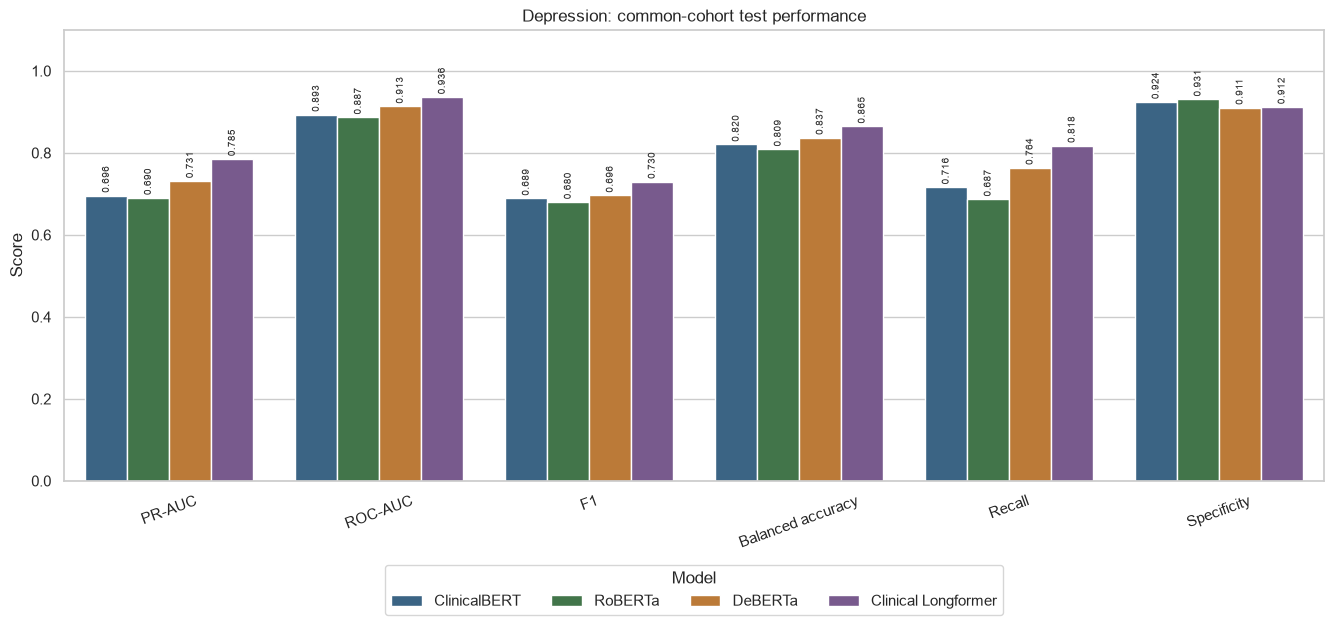

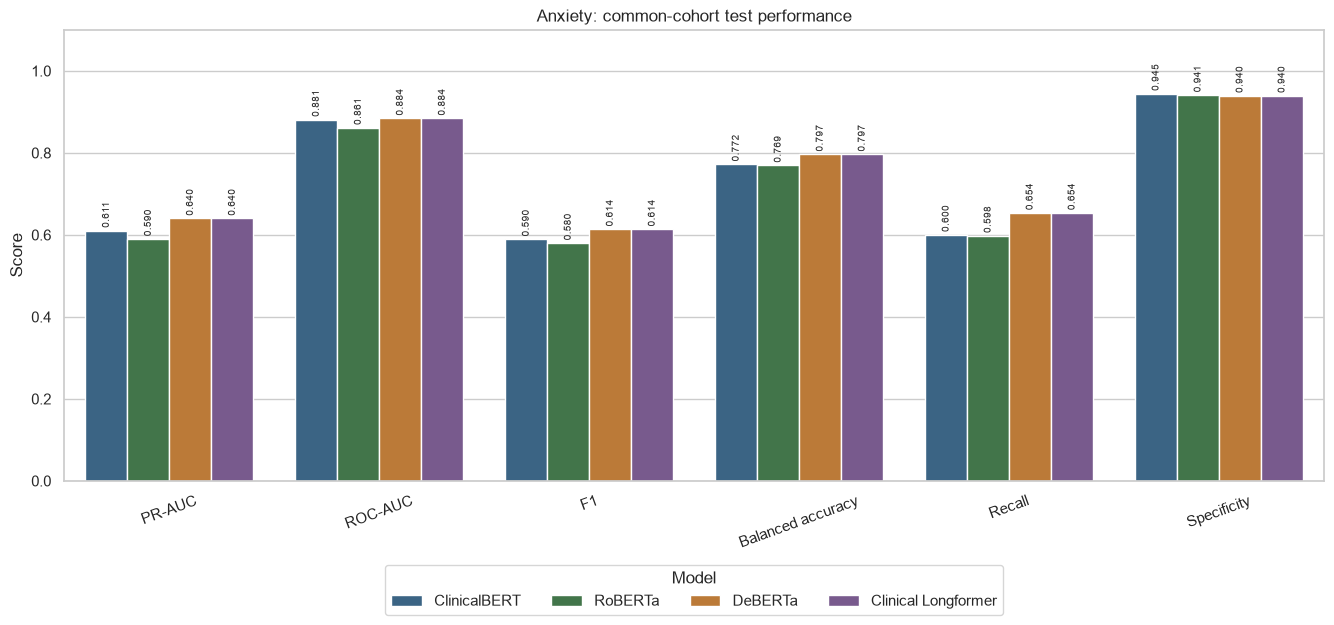

In [7]:
def save_figure(figure, task, filename):
    stem = TASK_DIRS[task]["figures"] / filename
    figure.savefig(stem.with_suffix(".png"), dpi=240, bbox_inches="tight", facecolor="white")
    figure.savefig(stem.with_suffix(".svg"), bbox_inches="tight", facecolor="white")

def ordered_palette(models):
    return [MODEL_COLORS[model] for model in models]

def label_vertical_bars(axis, decimals=3, suffix="", fontsize=8, rotation=0):
    value_format = f"%.{decimals}f{suffix}"
    for container in axis.containers:
        if hasattr(container, "patches"):
            axis.bar_label(container, fmt=value_format, padding=2, fontsize=fontsize, rotation=rotation)

def label_horizontal_bars(axis, decimals=3, suffix="", fontsize=9):
    value_format = f"%.{decimals}f{suffix}"
    for container in axis.containers:
        if hasattr(container, "patches"):
            axis.bar_label(container, fmt=value_format, padding=4, fontsize=fontsize)

PLOT_METRICS = ["pr_auc", "roc_auc", "f1", "balanced_accuracy", "recall", "specificity"]
METRIC_LABELS = {"pr_auc": "PR-AUC", "roc_auc": "ROC-AUC", "f1": "F1",
                 "balanced_accuracy": "Balanced accuracy", "recall": "Recall", "specificity": "Specificity"}

for task in TASKS:
    long_frame = common_evaluation_by_task[task].melt(id_vars="model", value_vars=PLOT_METRICS,
                                                       var_name="metric", value_name="score")
    long_frame["metric"] = long_frame["metric"].map(METRIC_LABELS)
    figure, axis = plt.subplots(figsize=(13.5, 6.5))
    sns.barplot(data=long_frame, x="metric", y="score", hue="model", hue_order=MODEL_ORDER,
                palette=MODEL_COLORS, ax=axis)
    axis.set(title=f"{task.title()}: common-cohort test performance", xlabel="", ylabel="Score", ylim=(0, 1.10))
    axis.tick_params(axis="x", rotation=20)
    label_vertical_bars(axis, decimals=3, fontsize=7, rotation=90)
    axis.legend(title="Model", loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=4, frameon=True)
    figure.tight_layout()
    save_figure(figure, task, "overall_metric_comparison")
    plt.show()
    plt.close(figure)

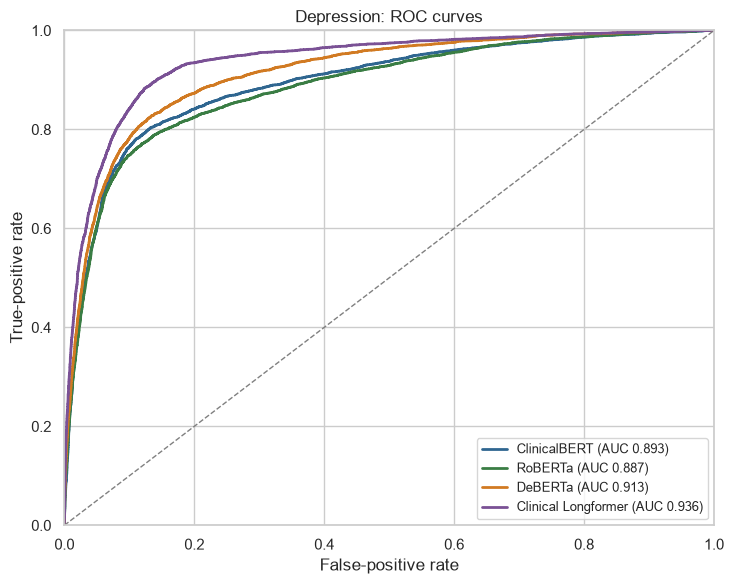

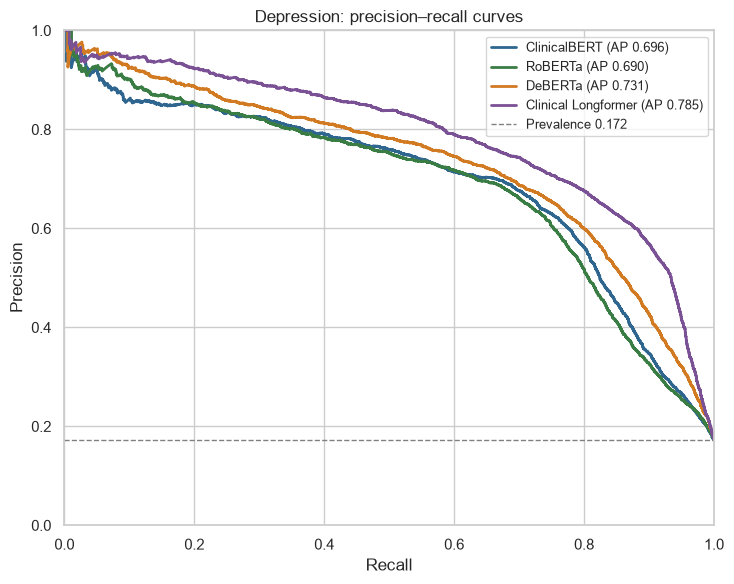

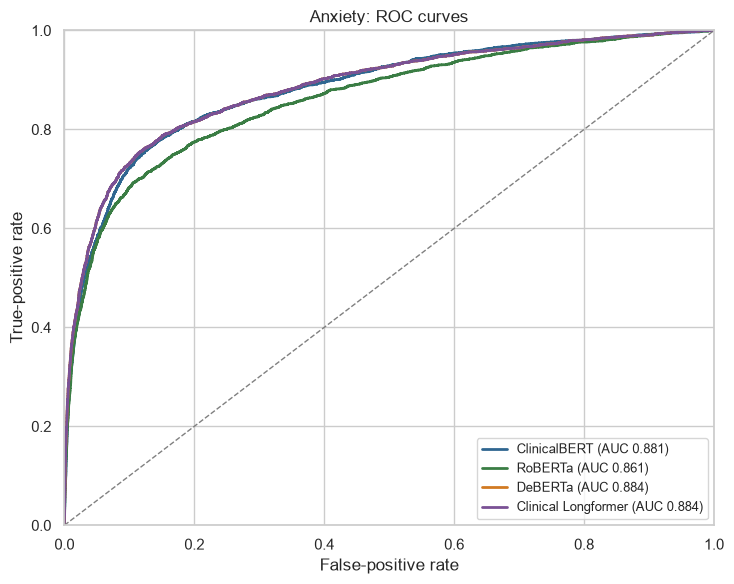

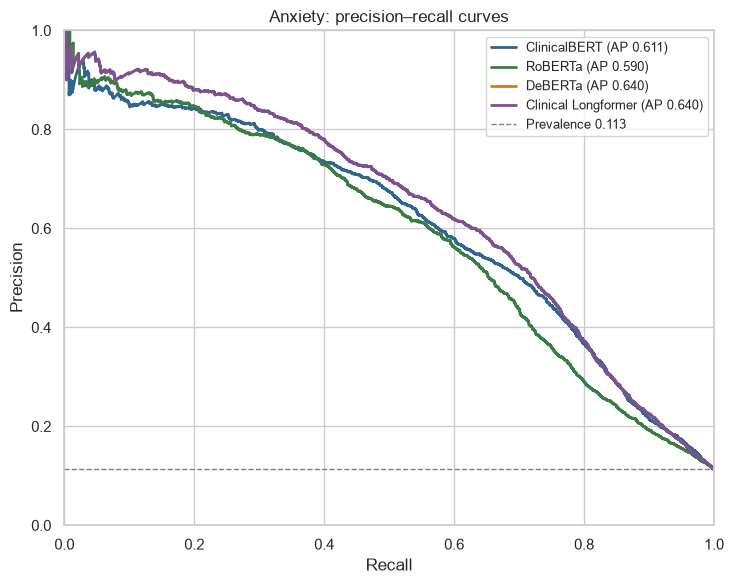

In [8]:
for task in TASKS:
    figure, axis = plt.subplots(figsize=(7.5, 6))
    for model in MODEL_ORDER:
        frame = common_frames_by_task[task][model]
        labels = frame["label"].to_numpy()
        probabilities = frame["positive_probability"].to_numpy()
        fpr, tpr, _ = roc_curve(labels, probabilities)
        axis.plot(fpr, tpr, color=MODEL_COLORS[model], linewidth=2,
                  label=f"{model} (AUC {roc_auc_score(labels, probabilities):.3f})")
    axis.plot([0, 1], [0, 1], "--", color="grey", linewidth=1)
    axis.set(title=f"{task.title()}: ROC curves", xlabel="False-positive rate", ylabel="True-positive rate",
             xlim=(0, 1), ylim=(0, 1))
    axis.legend(loc="lower right", fontsize=9)
    figure.tight_layout()
    save_figure(figure, task, "roc_curves")
    plt.show()
    plt.close(figure)

    figure, axis = plt.subplots(figsize=(7.5, 6))
    prevalence = common_frames_by_task[task][MODEL_ORDER[0]]["label"].mean()
    for model in MODEL_ORDER:
        frame = common_frames_by_task[task][model]
        labels = frame["label"].to_numpy()
        probabilities = frame["positive_probability"].to_numpy()
        precision_values, recall_values, _ = precision_recall_curve(labels, probabilities)
        axis.plot(recall_values, precision_values, color=MODEL_COLORS[model], linewidth=2,
                  label=f"{model} (AP {average_precision_score(labels, probabilities):.3f})")
    axis.axhline(prevalence, linestyle="--", color="grey", linewidth=1, label=f"Prevalence {prevalence:.3f}")
    axis.set(title=f"{task.title()}: precision–recall curves", xlabel="Recall", ylabel="Precision",
             xlim=(0, 1), ylim=(0, 1))
    axis.legend(loc="best", fontsize=9)
    figure.tight_layout()
    save_figure(figure, task, "precision_recall_curves")
    plt.show()
    plt.close(figure)

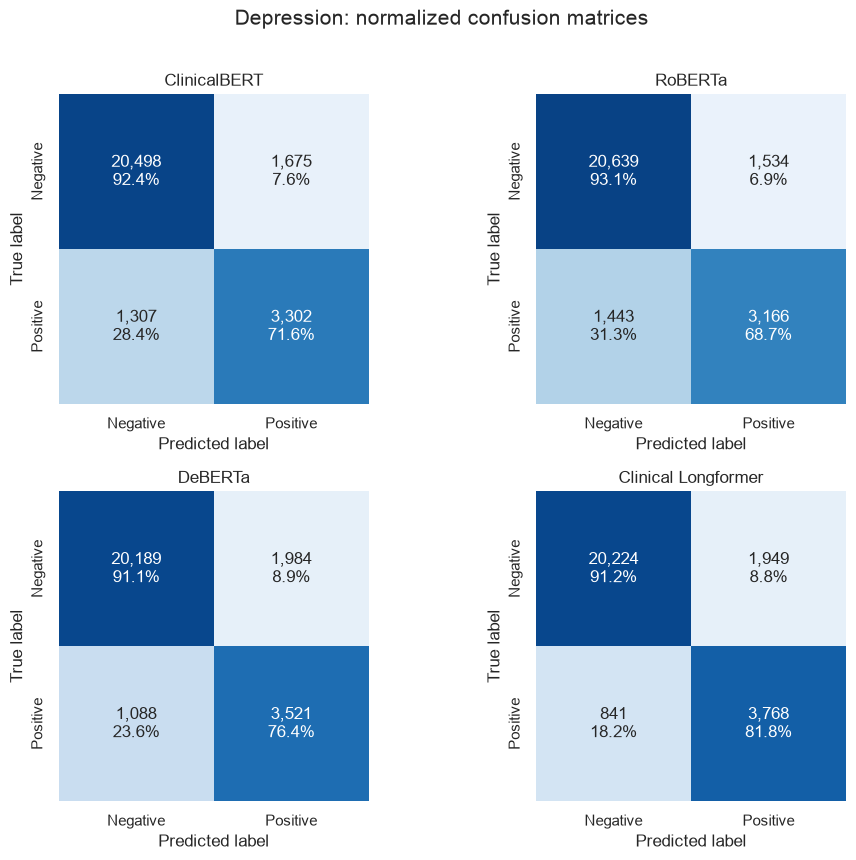

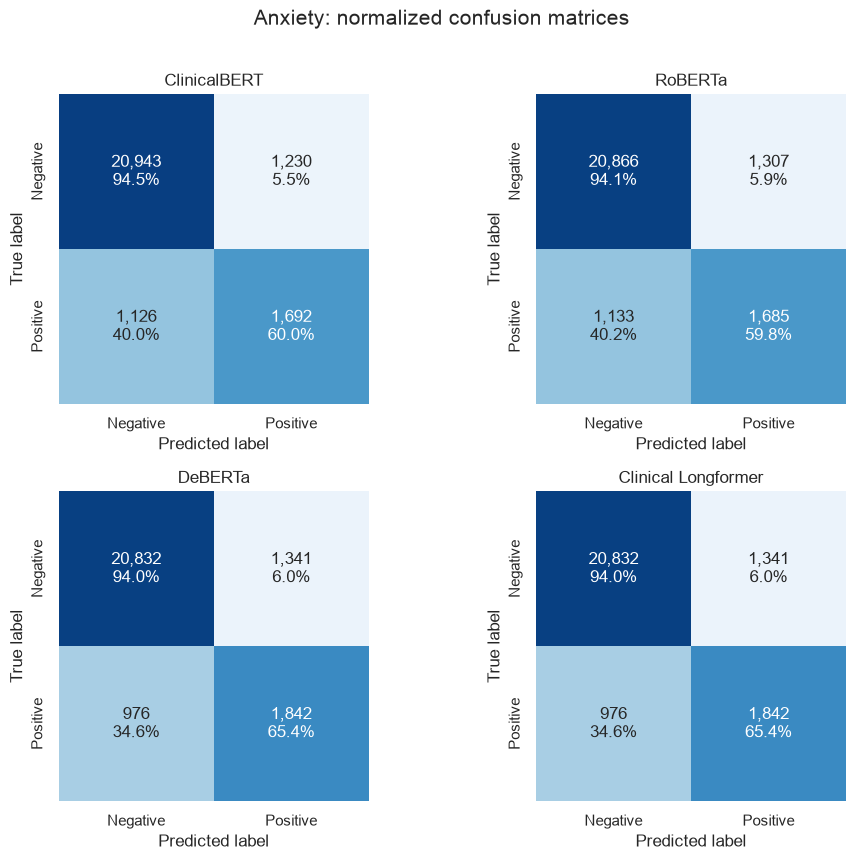

In [9]:
for task in TASKS:
    figure, axes = plt.subplots(2, 2, figsize=(10, 8.5))
    for axis, model in zip(axes.ravel(), MODEL_ORDER):
        frame = common_frames_by_task[task][model]
        matrix = confusion_matrix(frame["label"], frame["predicted_label"], labels=[0, 1])
        row_totals = matrix.sum(axis=1, keepdims=True)
        percentages = np.divide(matrix, row_totals, out=np.zeros_like(matrix, dtype=float), where=row_totals != 0)
        annotations = np.array([[f"{matrix[i, j]:,}\n{percentages[i, j]:.1%}" for j in range(2)] for i in range(2)])
        sns.heatmap(percentages, annot=annotations, fmt="", cmap="Blues", vmin=0, vmax=1,
                    cbar=False, square=True, ax=axis)
        axis.set(title=model, xlabel="Predicted label", ylabel="True label",
                 xticklabels=["Negative", "Positive"], yticklabels=["Negative", "Positive"])
    figure.suptitle(f"{task.title()}: normalized confusion matrices", y=1.01, fontsize=15)
    figure.tight_layout()
    save_figure(figure, task, "confusion_matrices")
    plt.show()
    plt.close(figure)

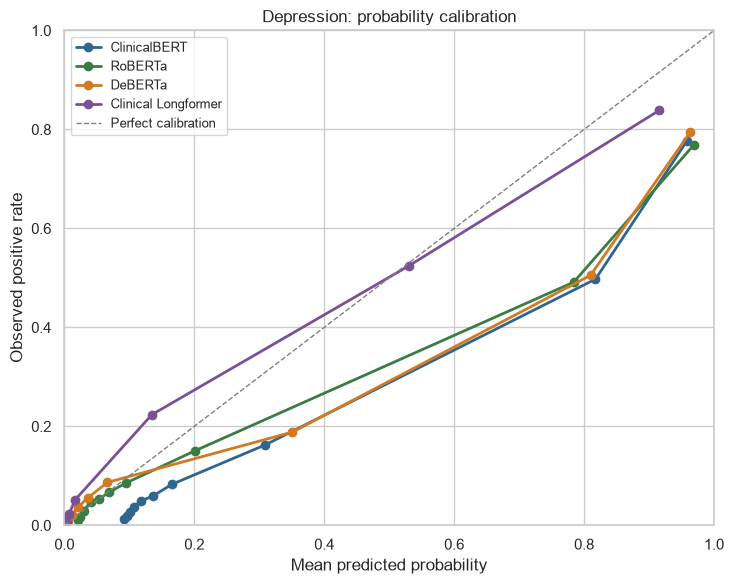

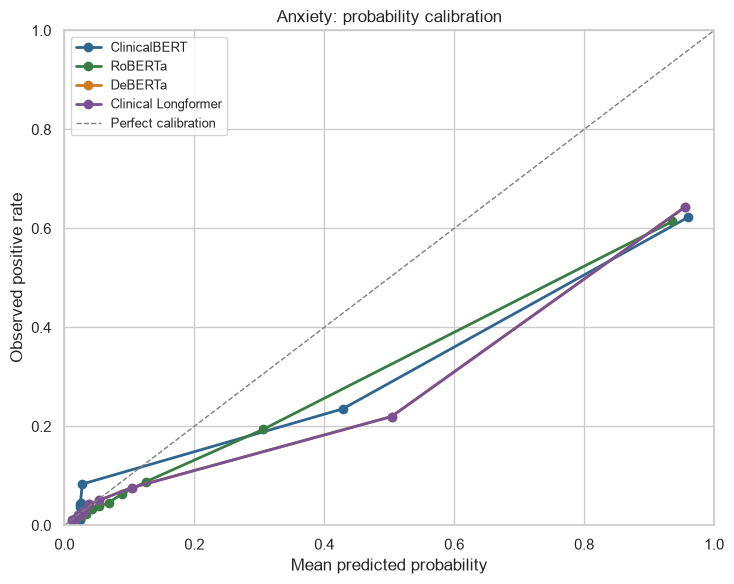

In [10]:
for task in TASKS:
    figure, axis = plt.subplots(figsize=(7.5, 6))
    for model in MODEL_ORDER:
        frame = common_frames_by_task[task][model]
        observed, predicted = calibration_curve(frame["label"], frame["positive_probability"],
                                                 n_bins=10, strategy="quantile")
        axis.plot(predicted, observed, marker="o", color=MODEL_COLORS[model], linewidth=2, label=model)
    axis.plot([0, 1], [0, 1], "--", color="grey", linewidth=1, label="Perfect calibration")
    axis.set(title=f"{task.title()}: probability calibration", xlabel="Mean predicted probability",
             ylabel="Observed positive rate", xlim=(0, 1), ylim=(0, 1))
    axis.legend(loc="best", fontsize=9)
    figure.tight_layout()
    save_figure(figure, task, "calibration_curves")
    plt.show()
    plt.close(figure)

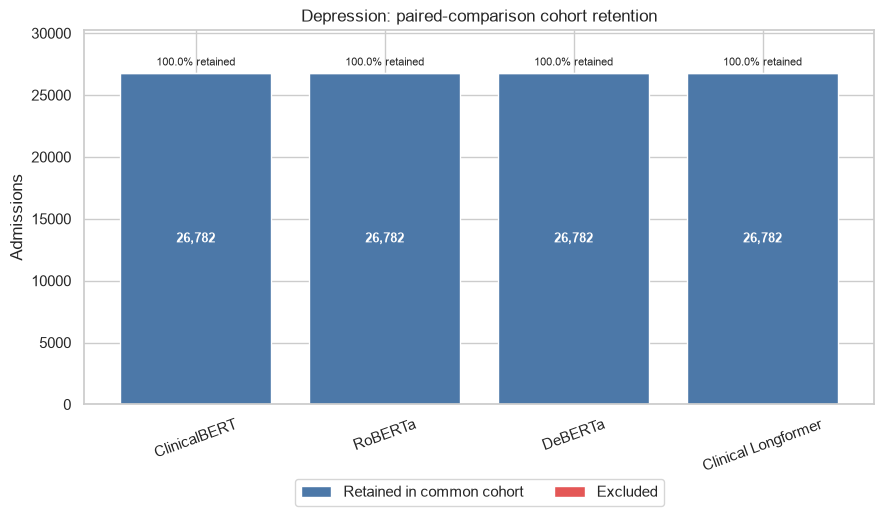

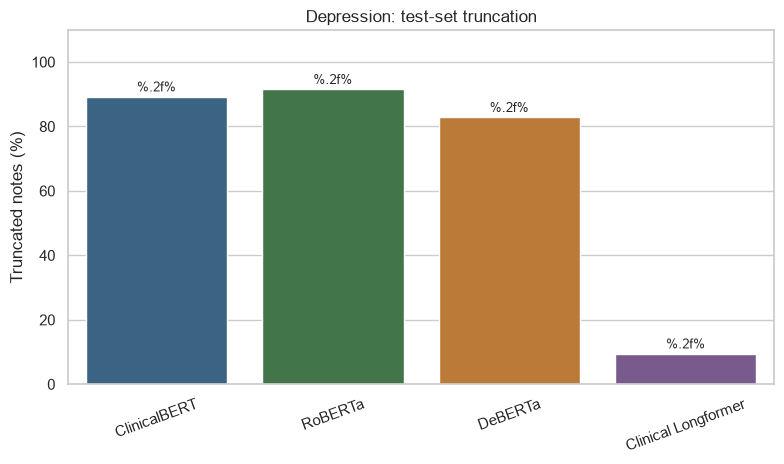

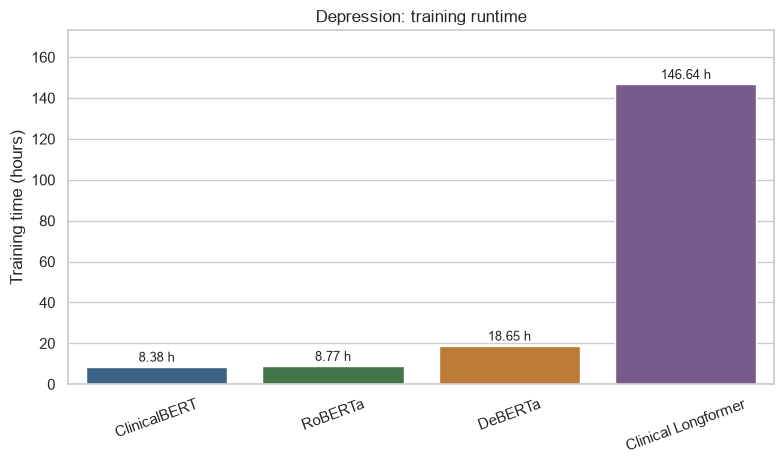

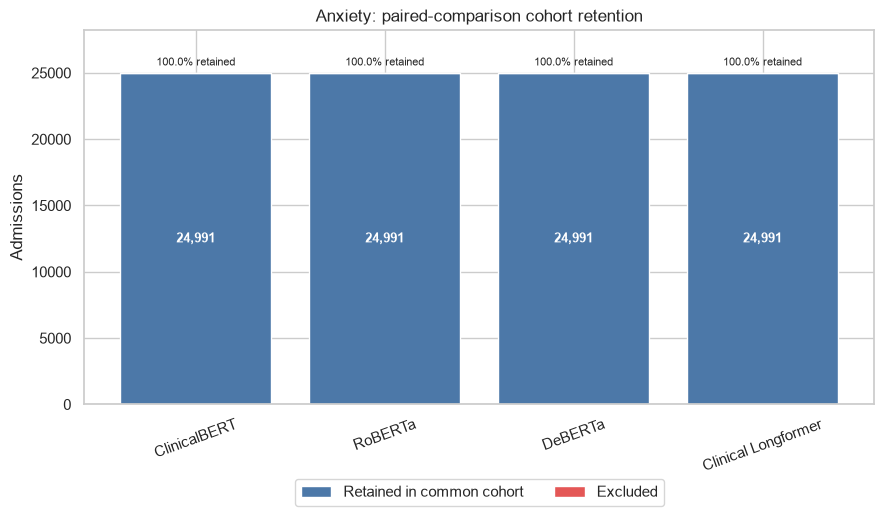

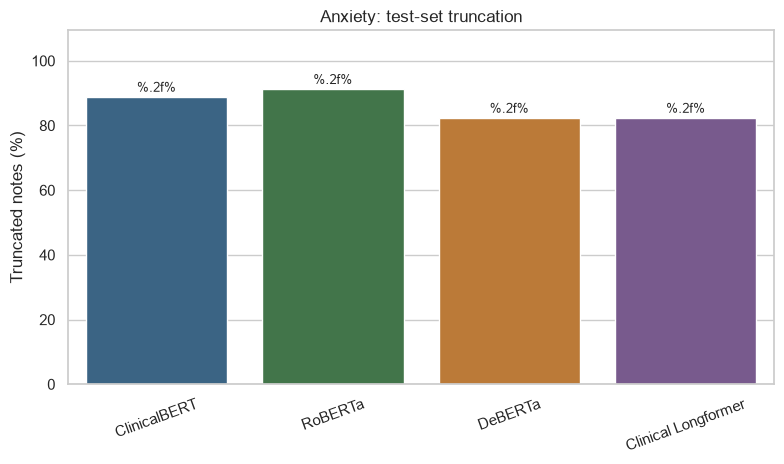

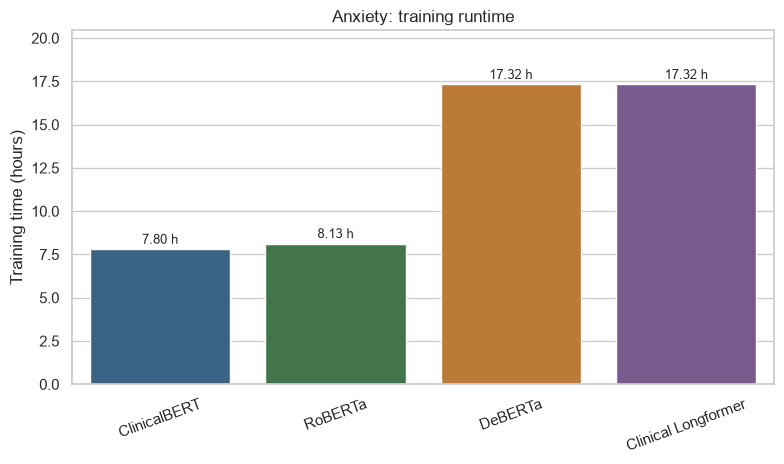

In [11]:
def test_truncation_rows(table):
    if table.empty or "truncation_percentage" not in table:
        return pd.DataFrame()
    frame = table.copy()
    if "split" in frame:
        frame = frame[frame["split"].astype(str).str.lower().eq("test")]
    return frame[["model", "truncation_percentage"]].drop_duplicates("model")

for task in TASKS:
    audit = cohort_audit_by_task[task]
    audit_plot = audit.set_index("model").loc[MODEL_ORDER].reset_index()
    figure, axis = plt.subplots(figsize=(9, 5.4))
    x_positions = np.arange(len(audit_plot))
    retained = audit_plot["common_admissions"].to_numpy()
    excluded = audit_plot["excluded_admissions"].to_numpy()
    original = audit_plot["original_admissions"].to_numpy()
    axis.bar(x_positions, retained, color="#4C78A8", label="Retained in common cohort")
    axis.bar(x_positions, excluded, bottom=retained, color="#E45756", label="Excluded")
    upper_padding = max(1, original.max() * 0.13)
    for position, retained_count, excluded_count, original_count in zip(x_positions, retained, excluded, original):
        axis.text(position, retained_count / 2, f"{retained_count:,}", ha="center", va="center",
                  color="white", fontsize=9, fontweight="bold")
        if excluded_count > 0:
            axis.text(position, retained_count + excluded_count / 2, f"{excluded_count:,}",
                      ha="center", va="center", color="white", fontsize=9, fontweight="bold")
        axis.text(position, original_count + upper_padding * 0.12,
                  f"{100 * retained_count / original_count:.1f}% retained", ha="center", va="bottom", fontsize=8)
    axis.set_xticks(x_positions, audit_plot["model"])
    axis.set_ylim(0, original.max() + upper_padding)
    axis.set(title=f"{task.title()}: paired-comparison cohort retention",
             xlabel="", ylabel="Admissions")
    axis.tick_params(axis="x", rotation=20)
    axis.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2)
    figure.tight_layout()
    save_figure(figure, task, "common_cohort_retention")
    plt.show()
    plt.close(figure)

    truncation_plot = test_truncation_rows(truncation_by_task[task])
    if not truncation_plot.empty:
        figure, axis = plt.subplots(figsize=(8, 4.8))
        sns.barplot(data=truncation_plot, x="model", y="truncation_percentage", order=MODEL_ORDER,
                    palette=ordered_palette(MODEL_ORDER), hue="model", legend=False, ax=axis)
        axis.set(title=f"{task.title()}: test-set truncation", xlabel="", ylabel="Truncated notes (%)")
        axis.set_ylim(0, max(1.0, truncation_plot["truncation_percentage"].max() * 1.20))
        label_vertical_bars(axis, decimals=2, suffix="%", fontsize=9)
        axis.tick_params(axis="x", rotation=20)
        figure.tight_layout()
        save_figure(figure, task, "test_truncation_percentage")
        plt.show()
        plt.close(figure)

    runtime = common_evaluation_by_task[task][["model", "training_hours"]].dropna()
    if not runtime.empty:
        figure, axis = plt.subplots(figsize=(8, 4.8))
        sns.barplot(data=runtime, x="model", y="training_hours", order=MODEL_ORDER,
                    palette=ordered_palette(MODEL_ORDER), hue="model", legend=False, ax=axis)
        axis.set(title=f"{task.title()}: training runtime", xlabel="", ylabel="Training time (hours)")
        axis.set_ylim(0, max(1.0, runtime["training_hours"].max() * 1.18))
        label_vertical_bars(axis, decimals=2, suffix=" h", fontsize=9)
        axis.tick_params(axis="x", rotation=20)
        figure.tight_layout()
        save_figure(figure, task, "training_runtime")
        plt.show()
        plt.close(figure)

## 8. Patient-clustered paired bootstrap

Admissions from the same patient are resampled together. Each replicate is shared across all models, preserving the paired design. Positive differences favour `model_a`. Ninety-five percent confidence intervals and empirical two-sided p-values are reported; Holm adjustment is applied separately within each task and metric.

In [12]:
def bootstrap_metric_value(metric, labels, predictions, probabilities):
    if metric == "pr_auc":
        return safe_auc(average_precision_score, labels, probabilities)
    if metric == "roc_auc":
        return safe_auc(roc_auc_score, labels, probabilities)
    if metric == "f1":
        return f1_score(labels, predictions, zero_division=0)
    if metric == "balanced_accuracy":
        return balanced_accuracy_score(labels, predictions)
    raise KeyError(metric)

def clustered_bootstrap(task, repeats, seed):
    frames = common_frames_by_task[task]
    reference = frames[MODEL_ORDER[0]].reset_index(drop=True)
    patient_indices = [np.asarray(indices, dtype=int)
                       for indices in reference.groupby("subject_id", sort=False).indices.values()]
    generator = np.random.default_rng(seed)
    results = np.full((repeats, len(MODEL_ORDER), len(BOOTSTRAP_METRICS)), np.nan)
    for repeat in range(repeats):
        sampled_patients = generator.integers(0, len(patient_indices), size=len(patient_indices))
        row_indices = np.concatenate([patient_indices[position] for position in sampled_patients])
        for model_index, model in enumerate(MODEL_ORDER):
            sample = frames[model].iloc[row_indices]
            labels = sample["label"].to_numpy(dtype=int)
            predictions = sample["predicted_label"].to_numpy(dtype=int)
            probabilities = sample["positive_probability"].to_numpy(dtype=float)
            for metric_index, metric in enumerate(BOOTSTRAP_METRICS):
                results[repeat, model_index, metric_index] = bootstrap_metric_value(
                    metric, labels, predictions, probabilities)
        if (repeat + 1) % max(1, repeats // 10) == 0:
            print(f"{task.title()}: {repeat + 1:,}/{repeats:,} bootstrap replicates")
    return results

bootstrap_start = time.time()
bootstrap_arrays = {task: clustered_bootstrap(task, BOOTSTRAP_REPEATS, SEED + index)
                    for index, task in enumerate(TASKS)}
print("Bootstrap runtime (minutes):", round((time.time() - bootstrap_start) / 60, 2))

Depression: 200/2,000 bootstrap replicates
Depression: 400/2,000 bootstrap replicates
Depression: 600/2,000 bootstrap replicates
Depression: 800/2,000 bootstrap replicates
Depression: 1,000/2,000 bootstrap replicates
Depression: 1,200/2,000 bootstrap replicates
Depression: 1,400/2,000 bootstrap replicates
Depression: 1,600/2,000 bootstrap replicates
Depression: 1,800/2,000 bootstrap replicates
Depression: 2,000/2,000 bootstrap replicates
Anxiety: 200/2,000 bootstrap replicates
Anxiety: 400/2,000 bootstrap replicates
Anxiety: 600/2,000 bootstrap replicates
Anxiety: 800/2,000 bootstrap replicates
Anxiety: 1,000/2,000 bootstrap replicates
Anxiety: 1,200/2,000 bootstrap replicates
Anxiety: 1,400/2,000 bootstrap replicates
Anxiety: 1,600/2,000 bootstrap replicates
Anxiety: 1,800/2,000 bootstrap replicates
Anxiety: 2,000/2,000 bootstrap replicates
Bootstrap runtime (minutes): 2.36


In [13]:
def holm_adjust(p_values):
    p_values = np.asarray(p_values, dtype=float)
    adjusted = np.full(len(p_values), np.nan)
    valid = np.flatnonzero(np.isfinite(p_values))
    if not len(valid):
        return adjusted
    order = valid[np.argsort(p_values[valid])]
    running_maximum = 0.0
    total = len(order)
    for rank, position in enumerate(order):
        candidate = min(1.0, (total - rank) * p_values[position])
        running_maximum = max(running_maximum, candidate)
        adjusted[position] = running_maximum
    return adjusted

alpha = 1 - CONFIDENCE_LEVEL
bootstrap_comparisons_by_task = {}
bootstrap_model_summary_by_task = {}
for task in TASKS:
    arrays = bootstrap_arrays[task]
    observed = common_evaluation_by_task[task].set_index("model")
    rows = []
    for metric_index, metric in enumerate(BOOTSTRAP_METRICS):
        for model_a, model_b in combinations(MODEL_ORDER, 2):
            a_index, b_index = MODEL_ORDER.index(model_a), MODEL_ORDER.index(model_b)
            differences = arrays[:, a_index, metric_index] - arrays[:, b_index, metric_index]
            differences = differences[np.isfinite(differences)]
            non_positive = (np.sum(differences <= 0) + 1) / (len(differences) + 1)
            non_negative = (np.sum(differences >= 0) + 1) / (len(differences) + 1)
            rows.append({"metric": metric, "model_a": model_a, "model_b": model_b,
                         "observed_difference_a_minus_b": observed.loc[model_a, metric] - observed.loc[model_b, metric],
                         "ci_lower": np.quantile(differences, alpha / 2),
                         "ci_upper": np.quantile(differences, 1 - alpha / 2),
                         "bootstrap_two_sided_p": min(1.0, 2 * min(non_positive, non_negative)),
                         "replicates_used": len(differences)})
    comparisons = pd.DataFrame(rows)
    comparisons["holm_adjusted_p"] = comparisons.groupby("metric", group_keys=False)[
        "bootstrap_two_sided_p"].transform(holm_adjust)
    comparisons["significant_after_holm"] = comparisons["holm_adjusted_p"] < 0.05
    bootstrap_comparisons_by_task[task] = comparisons
    comparisons.to_csv(TASK_DIRS[task]["tables"] / "patient_clustered_bootstrap_comparisons.csv", index=False)

    summary_rows = []
    for metric_index, metric in enumerate(BOOTSTRAP_METRICS):
        for model_index, model in enumerate(MODEL_ORDER):
            values = arrays[:, model_index, metric_index]
            values = values[np.isfinite(values)]
            summary_rows.append({"model": model, "metric": metric, "observed": observed.loc[model, metric],
                                 "ci_lower": np.quantile(values, alpha / 2),
                                 "ci_upper": np.quantile(values, 1 - alpha / 2)})
    bootstrap_model_summary_by_task[task] = pd.DataFrame(summary_rows)
    bootstrap_model_summary_by_task[task].to_csv(
        TASK_DIRS[task]["tables"] / "model_metric_bootstrap_confidence_intervals.csv", index=False)
    display(Markdown(f"### {task.title()} paired-bootstrap comparisons"))
    display(comparisons.round(5))

### Depression paired-bootstrap comparisons

,metric,model_a,model_b,observed_difference_a_minus_b,ci_lower,ci_upper,bootstrap_two_sided_p,replicates_used,holm_adjusted_p,significant_after_holm
0,pr_auc,ClinicalBERT,RoBERTa,0.00557,-0.00201,0.01334,0.15492,2000,0.15492,False
1,pr_auc,ClinicalBERT,DeBERTa,-0.03550,-0.04397,-0.02699,0.00100,2000,0.00600,True
2,pr_auc,ClinicalBERT,Clinical Longformer,-0.08927,-0.10073,-0.07792,0.00100,2000,0.00600,True
3,pr_auc,RoBERTa,DeBERTa,-0.04108,-0.04976,-0.03263,0.00100,2000,0.00600,True
4,pr_auc,RoBERTa,Clinical Longformer,-0.09484,-0.10595,-0.08340,0.00100,2000,0.00600,True
5,pr_auc,DeBERTa,Clinical Longformer,-0.05376,-0.06287,-0.04470,0.00100,2000,0.00600,True
6,roc_auc,ClinicalBERT,RoBERTa,0.00656,0.00242,0.01063,0.00100,2000,0.00600,True
7,roc_auc,ClinicalBERT,DeBERTa,-0.01993,-0.02433,-0.01600,0.00100,2000,0.00600,True
8,roc_auc,ClinicalBERT,Clinical Longformer,-0.04277,-0.04816,-0.03740,0.00100,2000,0.00600,True
9,roc_auc,RoBERTa,DeBERTa,-0.02649,-0.03118,-0.02199,0.00100,2000,0.00600,True


### Anxiety paired-bootstrap comparisons

,metric,model_a,model_b,observed_difference_a_minus_b,ci_lower,ci_upper,bootstrap_two_sided_p,replicates_used,holm_adjusted_p,significant_after_holm
0,pr_auc,ClinicalBERT,RoBERTa,0.02055,0.00878,0.03224,0.00200,2000,0.00600,True
1,pr_auc,ClinicalBERT,DeBERTa,-0.02949,-0.04090,-0.01845,0.00100,2000,0.00600,True
2,pr_auc,ClinicalBERT,Clinical Longformer,-0.02949,-0.04090,-0.01845,0.00100,2000,0.00600,True
3,pr_auc,RoBERTa,DeBERTa,-0.05004,-0.06116,-0.03853,0.00100,2000,0.00600,True
4,pr_auc,RoBERTa,Clinical Longformer,-0.05004,-0.06116,-0.03853,0.00100,2000,0.00600,True
5,pr_auc,DeBERTa,Clinical Longformer,0.00000,0.00000,0.00000,1.00000,2000,1.00000,False
6,roc_auc,ClinicalBERT,RoBERTa,0.01984,0.01400,0.02625,0.00100,2000,0.00600,True
7,roc_auc,ClinicalBERT,DeBERTa,-0.00306,-0.00828,0.00193,0.25587,2000,0.76762,False
8,roc_auc,ClinicalBERT,Clinical Longformer,-0.00306,-0.00828,0.00193,0.25587,2000,0.76762,False
9,roc_auc,RoBERTa,DeBERTa,-0.02291,-0.02849,-0.01747,0.00100,2000,0.00600,True


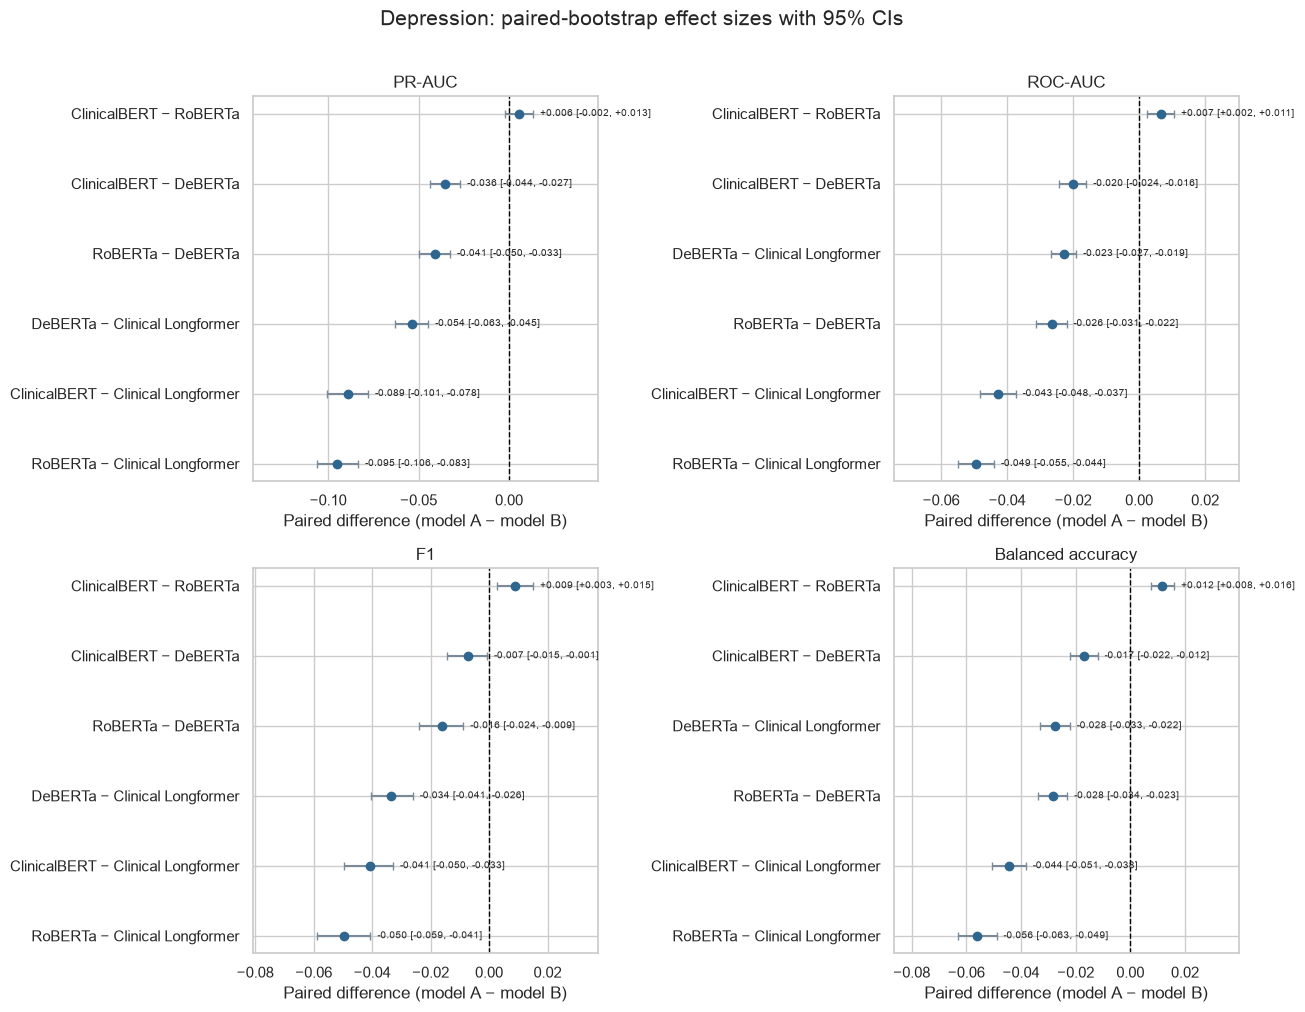

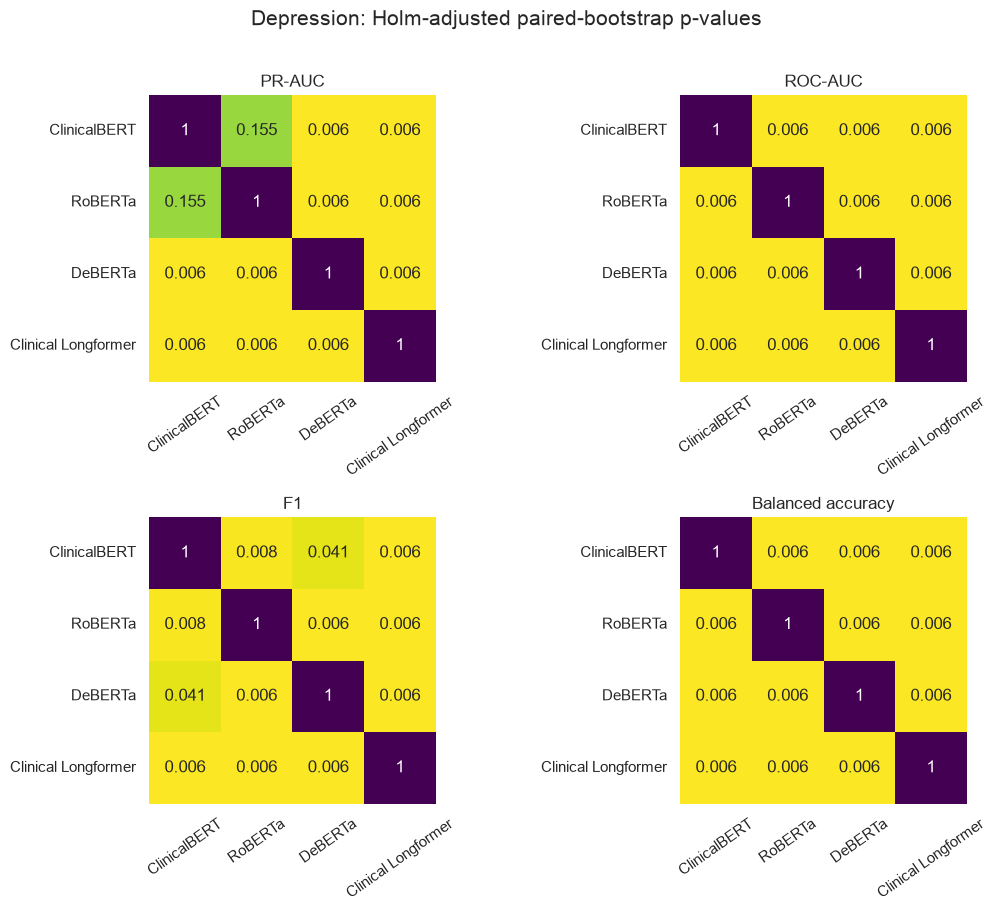

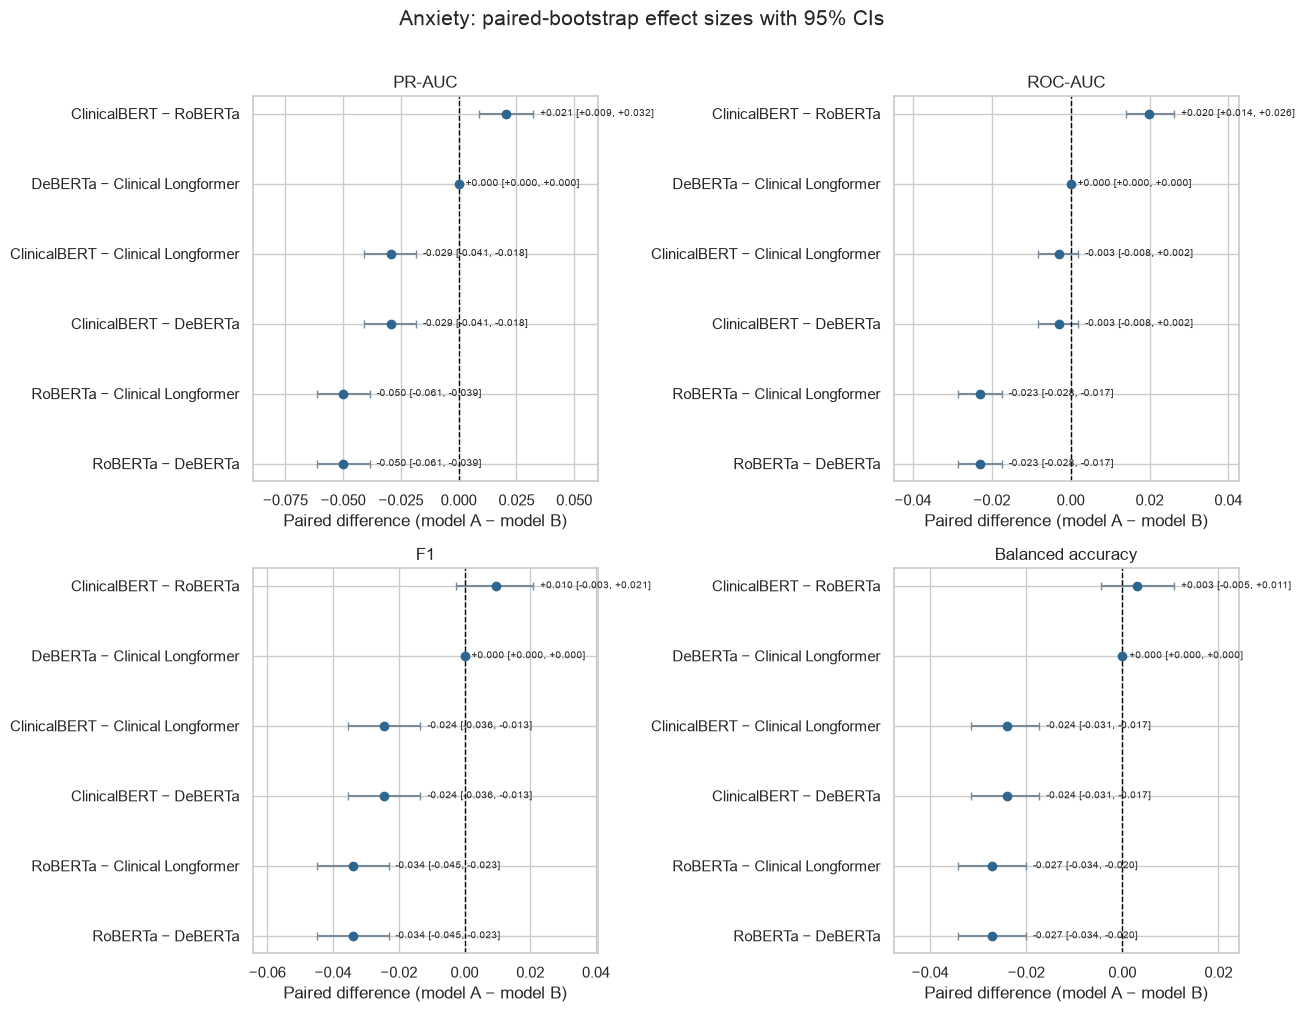

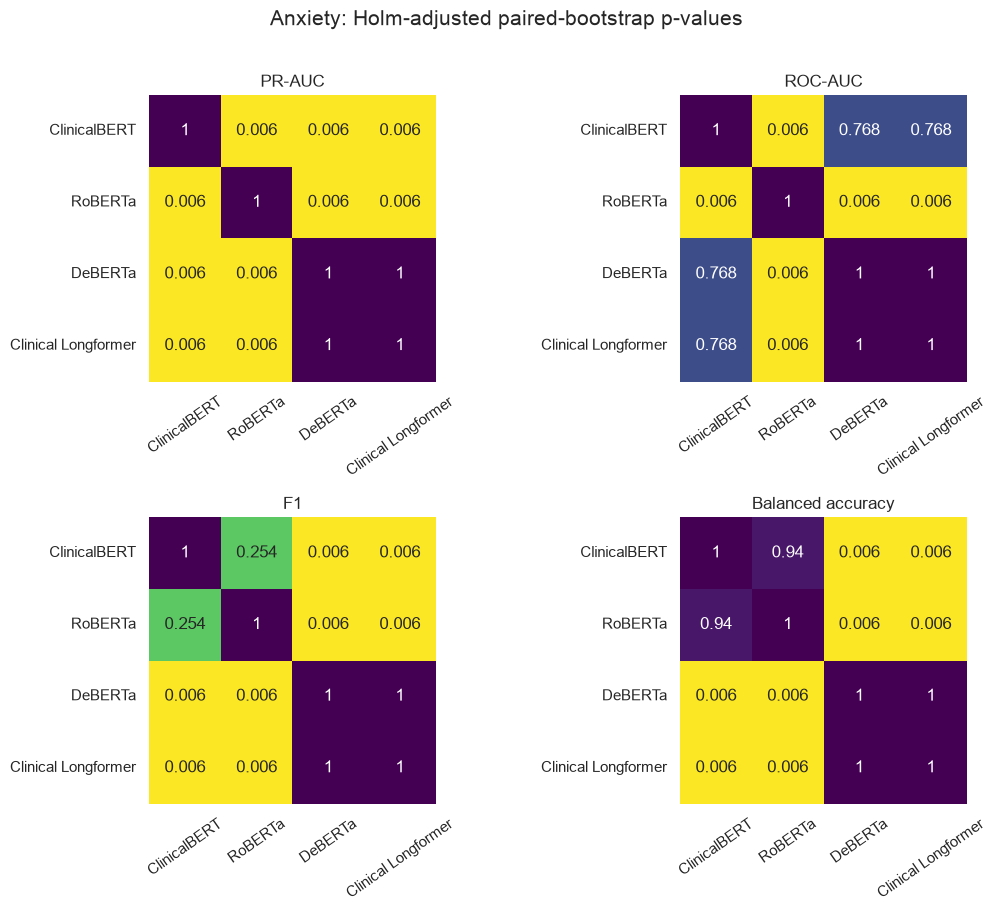

In [14]:
for task in TASKS:
    comparisons = bootstrap_comparisons_by_task[task]
    figure, axes = plt.subplots(2, 2, figsize=(13, 10))
    for axis, metric in zip(axes.ravel(), BOOTSTRAP_METRICS):
        frame = comparisons[comparisons["metric"] == metric].copy()
        frame["comparison"] = frame["model_a"] + " − " + frame["model_b"]
        frame = frame.sort_values("observed_difference_a_minus_b")
        x = frame["observed_difference_a_minus_b"].to_numpy()
        lower = x - frame["ci_lower"].to_numpy()
        upper = frame["ci_upper"].to_numpy() - x
        axis.errorbar(x, frame["comparison"], xerr=np.vstack([lower, upper]), fmt="o", color="#2F6690",
                      ecolor="#7A8A99", capsize=3)
        for y_position, (point, ci_low, ci_high) in enumerate(zip(x, frame["ci_lower"], frame["ci_upper"])):
            axis.annotate(f"{point:+.3f} [{ci_low:+.3f}, {ci_high:+.3f}]",
                          xy=(ci_high, y_position), xytext=(5, 0), textcoords="offset points",
                          va="center", fontsize=7)
        axis.axvline(0, linestyle="--", color="black", linewidth=1)
        axis.set(title=METRIC_LABELS.get(metric, metric), xlabel="Paired difference (model A − model B)", ylabel="")
        axis.margins(x=0.30)
    figure.suptitle(f"{task.title()}: paired-bootstrap effect sizes with 95% CIs", y=1.01, fontsize=15)
    figure.tight_layout()
    save_figure(figure, task, "bootstrap_effect_size_forest_plots")
    plt.show()
    plt.close(figure)

    figure, axes = plt.subplots(2, 2, figsize=(11, 9))
    for axis, metric in zip(axes.ravel(), BOOTSTRAP_METRICS):
        matrix = pd.DataFrame(np.nan, index=MODEL_ORDER, columns=MODEL_ORDER)
        for _, row in comparisons[comparisons["metric"] == metric].iterrows():
            matrix.loc[row["model_a"], row["model_b"]] = row["holm_adjusted_p"]
            matrix.loc[row["model_b"], row["model_a"]] = row["holm_adjusted_p"]
        matrix_array = matrix.to_numpy(copy=True)
        np.fill_diagonal(matrix_array, 1.0)
        matrix = pd.DataFrame(matrix_array, index=matrix.index, columns=matrix.columns)
        sns.heatmap(matrix, annot=True, fmt=".3g", cmap="viridis_r", vmin=0, vmax=1,
                    square=True, cbar=False, ax=axis)
        axis.set_title(METRIC_LABELS.get(metric, metric))
        axis.tick_params(axis="x", rotation=35)
        axis.tick_params(axis="y", rotation=0)
    figure.suptitle(f"{task.title()}: Holm-adjusted paired-bootstrap p-values", y=1.01, fontsize=15)
    figure.tight_layout()
    save_figure(figure, task, "bootstrap_adjusted_p_value_heatmaps")
    plt.show()
    plt.close(figure)

## 9. Exact paired McNemar tests

McNemar tests compare paired classification errors at each model's frozen validation-selected threshold. Holm correction is applied within each task.

### Depression McNemar tests

,model_a,model_b,a_correct_b_wrong,a_wrong_b_correct,discordant_pairs,exact_p,holm_adjusted_p,significant_after_holm
0,ClinicalBERT,RoBERTa,384,389,773,0.885615,0.885615,False
1,ClinicalBERT,DeBERTa,591,501,1092,0.007048,0.019023,True
2,ClinicalBERT,Clinical Longformer,623,815,1438,0.000000,0.000002,True
3,RoBERTa,DeBERTa,641,546,1187,0.006341,0.019023,True
4,RoBERTa,Clinical Longformer,645,832,1477,0.000001,0.000005,True
5,DeBERTa,Clinical Longformer,552,834,1386,0.000000,0.000000,True


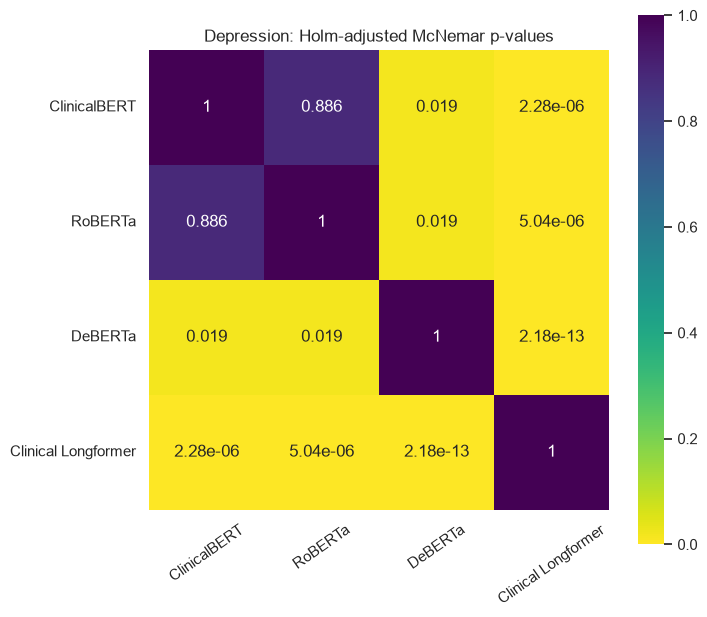

### Anxiety McNemar tests

,model_a,model_b,a_correct_b_wrong,a_wrong_b_correct,discordant_pairs,exact_p,holm_adjusted_p,significant_after_holm
0,ClinicalBERT,RoBERTa,632,548,1180,0.015647,0.062587,False
1,ClinicalBERT,DeBERTa,510,549,1059,0.242910,0.728729,False
2,ClinicalBERT,Clinical Longformer,510,549,1059,0.242910,0.728729,False
3,RoBERTa,DeBERTa,412,535,947,0.000072,0.000432,True
4,RoBERTa,Clinical Longformer,412,535,947,0.000072,0.000432,True
5,DeBERTa,Clinical Longformer,0,0,0,1.000000,1.000000,False


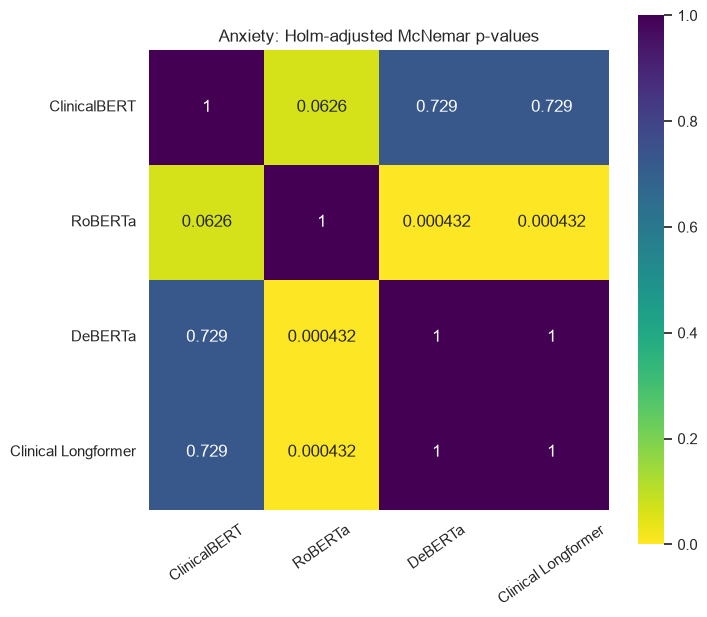

In [15]:
mcnemar_by_task = {}
for task in TASKS:
    rows = []
    frames = common_frames_by_task[task]
    for model_a, model_b in combinations(MODEL_ORDER, 2):
        correct_a = frames[model_a]["predicted_label"].to_numpy() == frames[model_a]["label"].to_numpy()
        correct_b = frames[model_b]["predicted_label"].to_numpy() == frames[model_b]["label"].to_numpy()
        a_only = int(np.sum(correct_a & ~correct_b))
        b_only = int(np.sum(~correct_a & correct_b))
        discordant = a_only + b_only
        p_value = binomtest(min(a_only, b_only), discordant, 0.5).pvalue if discordant else 1.0
        rows.append({"model_a": model_a, "model_b": model_b, "a_correct_b_wrong": a_only,
                     "a_wrong_b_correct": b_only, "discordant_pairs": discordant, "exact_p": p_value})
    table = pd.DataFrame(rows)
    table["holm_adjusted_p"] = holm_adjust(table["exact_p"])
    table["significant_after_holm"] = table["holm_adjusted_p"] < 0.05
    mcnemar_by_task[task] = table
    table.to_csv(TASK_DIRS[task]["tables"] / "mcnemar_pairwise_tests.csv", index=False)
    display(Markdown(f"### {task.title()} McNemar tests"))
    display(table.round(6))

    matrix = pd.DataFrame(np.nan, index=MODEL_ORDER, columns=MODEL_ORDER)
    for _, row in table.iterrows():
        matrix.loc[row["model_a"], row["model_b"]] = row["holm_adjusted_p"]
        matrix.loc[row["model_b"], row["model_a"]] = row["holm_adjusted_p"]
    matrix_array = matrix.to_numpy(copy=True)
    np.fill_diagonal(matrix_array, 1.0)
    matrix = pd.DataFrame(matrix_array, index=matrix.index, columns=matrix.columns)
    figure, axis = plt.subplots(figsize=(7.5, 6.5))
    sns.heatmap(matrix, annot=True, fmt=".3g", cmap="viridis_r", vmin=0, vmax=1, square=True, ax=axis)
    axis.set_title(f"{task.title()}: Holm-adjusted McNemar p-values")
    axis.tick_params(axis="x", rotation=35)
    axis.tick_params(axis="y", rotation=0)
    figure.tight_layout()
    save_figure(figure, task, "mcnemar_adjusted_p_value_heatmap")
    plt.show()
    plt.close(figure)

## 10. Demographic and comorbidity subgroup metadata

The notebook searches the configured task dataset for age, sex and comorbidity load. If these fields are stored elsewhere, change `DEMOGRAPHIC_PATHS`. If comorbidity load must be calculated from binary condition fields, list them in `COMORBIDITY_COMPONENT_COLUMNS`. Missing metadata is reported clearly and does not invalidate the overall comparison.

In [16]:
COLUMN_CANDIDATES = {
    "age": ["age", "anchor_age", "admission_age", "age_at_admission"],
    "sex": ["sex", "gender"],
    "comorbidity_load": ["comorbidity_load", "comorbidity_count", "number_of_comorbidities",
                         "num_comorbidities", "charlson_comorbidity_index", "charlson_index", "cci"],
}
COLUMN_OVERRIDES = {"age": None, "sex": None, "comorbidity_load": None}
COMORBIDITY_COMPONENT_COLUMNS = []

def available_columns(path):
    if path.suffix.lower() in {".parquet", ".pq"}:
        import pyarrow.parquet as parquet
        return parquet.ParquetFile(path).schema.names
    if path.suffix.lower() == ".csv":
        return pd.read_csv(path, nrows=0).columns.tolist()
    raise ValueError(f"Unsupported demographic file type: {path.suffix}")

def read_selected_columns(path, columns):
    return pd.read_parquet(path, columns=columns) if path.suffix.lower() in {".parquet", ".pq"} else pd.read_csv(path, usecols=columns)

def resolve_metadata_column(columns, concept):
    override = COLUMN_OVERRIDES[concept]
    if override:
        if override not in columns:
            raise ValueError(f"Configured {concept} column not found: {override}")
        return override
    lookup = {column.lower(): column for column in columns}
    return next((lookup[candidate.lower()] for candidate in COLUMN_CANDIDATES[concept]
                 if candidate.lower() in lookup), None)

def load_subgroup_metadata(task):
    path = Path(DEMOGRAPHIC_PATHS[task])
    if not path.exists():
        return None, {"status": "missing file", "path": str(path), "subgroup_columns": ""}
    columns = available_columns(path)
    age_column = resolve_metadata_column(columns, "age")
    sex_column = resolve_metadata_column(columns, "sex")
    comorbidity_column = resolve_metadata_column(columns, "comorbidity_load")
    if "hadm_id" not in columns:
        return None, {"status": "hadm_id missing", "path": str(path), "subgroup_columns": ""}
    ids = [column for column in ["subject_id", "hadm_id"] if column in columns]
    selected = list(dict.fromkeys(ids + [column for column in [age_column, sex_column, comorbidity_column]
                                         if column] + COMORBIDITY_COMPONENT_COLUMNS))
    metadata = read_selected_columns(path, selected).drop_duplicates("hadm_id")
    rename_map = {column: concept for concept, column in {
        "age": age_column, "sex": sex_column, "comorbidity_load": comorbidity_column}.items() if column}
    metadata = metadata.rename(columns=rename_map)
    if "comorbidity_load" not in metadata and COMORBIDITY_COMPONENT_COLUMNS:
        missing = set(COMORBIDITY_COMPONENT_COLUMNS).difference(metadata.columns)
        if missing:
            raise ValueError(f"Comorbidity component columns missing: {sorted(missing)}")
        metadata["comorbidity_load"] = metadata[COMORBIDITY_COMPONENT_COLUMNS].fillna(0).astype(float).sum(axis=1)
    found = [column for column in ["age", "sex", "comorbidity_load"] if column in metadata]
    return metadata, {"status": "loaded", "path": str(path), "subgroup_columns": ", ".join(found)}

metadata_by_task = {}
for task in TASKS:
    metadata_by_task[task], audit = load_subgroup_metadata(task)
    audit_table = pd.DataFrame([audit])
    audit_table.to_csv(TASK_DIRS[task]["tables"] / "subgroup_metadata_audit.csv", index=False)
    display(Markdown(f"### {task.title()} subgroup metadata audit"))
    display(audit_table)

### Depression subgroup metadata audit

,status,path,subgroup_columns
0,loaded,/Users/purnaperamune/Documents/GitHub/P000464S...,"age, sex"


### Anxiety subgroup metadata audit

,status,path,subgroup_columns
0,loaded,/Users/purnaperamune/Documents/GitHub/P000464S...,"age, sex"


In [17]:
def add_subgroup_bands(metadata):
    metadata = metadata.copy()
    if "age" in metadata:
        metadata["age"] = pd.to_numeric(metadata["age"], errors="coerce")
        metadata["age_band"] = pd.cut(metadata["age"], bins=[59, 69, 79, 89, np.inf],
                                      labels=["60–69", "70–79", "80–89", "90+"], right=True)
    if "sex" in metadata:
        metadata["sex_group"] = metadata["sex"].astype(str).str.strip().str.upper().replace(
            {"M": "Male", "MALE": "Male", "F": "Female", "FEMALE": "Female"})
    if "comorbidity_load" in metadata:
        metadata["comorbidity_load"] = pd.to_numeric(metadata["comorbidity_load"], errors="coerce")
        metadata["comorbidity_band"] = pd.cut(metadata["comorbidity_load"],
            bins=[-np.inf, 0, 2, 4, np.inf], labels=["0", "1–2", "3–4", "5+"], right=True)
    return metadata

subgroup_by_task = {}
subgroup_gap_by_task = {}
for task in TASKS:
    metadata = metadata_by_task[task]
    rows = []
    if metadata is not None:
        metadata = add_subgroup_bands(metadata)
        variables = [column for column in ["age_band", "sex_group", "comorbidity_band"] if column in metadata]
        for model in MODEL_ORDER:
            merge_keys = ["hadm_id", "subject_id"] if "subject_id" in metadata else ["hadm_id"]
            merged = common_frames_by_task[task][model].merge(metadata, on=merge_keys, how="left", validate="one_to_one")
            for variable in variables:
                for group_name, group_frame in merged.dropna(subset=[variable]).groupby(variable, observed=True):
                    if len(group_frame) < MIN_SUBGROUP_ADMISSIONS:
                        continue
                    rows.append({"model": model, "subgroup_variable": variable, "subgroup": str(group_name),
                                 "admissions": len(group_frame), "patients": group_frame["subject_id"].nunique(),
                                 "prevalence": group_frame["label"].mean(), **calculate_metrics(group_frame)})
    subgroup = pd.DataFrame(rows)
    subgroup_by_task[task] = subgroup
    subgroup.to_csv(TASK_DIRS[task]["tables"] / "subgroup_performance.csv", index=False)
    display(Markdown(f"### {task.title()} subgroup performance"))
    if subgroup.empty:
        display(Markdown("**Not produced:** supply age, sex and comorbidity metadata in Section 10, then rerun."))
        subgroup_gap_by_task[task] = pd.DataFrame()
        continue
    display(subgroup[["model", "subgroup_variable", "subgroup", "admissions", "patients", "prevalence",
                      "balanced_accuracy", "recall", "specificity", "f1", "roc_auc", "pr_auc"]].round(4))
    gap_rows = []
    for (model, variable), group in subgroup.groupby(["model", "subgroup_variable"]):
        for metric in ["pr_auc", "recall", "specificity", "balanced_accuracy"]:
            values = group[metric].dropna()
            gap_rows.append({"model": model, "subgroup_variable": variable, "metric": metric,
                             "max_minus_min": values.max() - values.min() if len(values) >= 2 else np.nan})
    subgroup_gap_by_task[task] = pd.DataFrame(gap_rows)
    subgroup_gap_by_task[task].to_csv(TASK_DIRS[task]["tables"] / "subgroup_performance_gaps.csv", index=False)

### Depression subgroup performance

,model,subgroup_variable,subgroup,admissions,patients,prevalence,balanced_accuracy,recall,specificity,f1,roc_auc,pr_auc
0,ClinicalBERT,age_band,60–69,9651,4594,0.2047,0.8342,0.7495,0.9190,0.7262,0.9001,0.7408
1,ClinicalBERT,age_band,70–79,8411,3988,0.1604,0.8229,0.7265,0.9194,0.6763,0.8953,0.6821
2,ClinicalBERT,age_band,80–89,6462,3009,0.1424,0.7944,0.6533,0.9356,0.6400,0.8770,0.6229
3,ClinicalBERT,age_band,90+,2258,1116,0.1612,0.7961,0.6593,0.9329,0.6566,0.8878,0.6764
4,ClinicalBERT,sex_group,Female,13644,5818,0.2027,0.8212,0.7383,0.9042,0.6981,0.8870,0.7068
5,ClinicalBERT,sex_group,Male,13138,5743,0.1403,0.8138,0.6837,0.9440,0.6745,0.8978,0.6801
6,RoBERTa,age_band,60–69,9651,4594,0.2047,0.8206,0.7161,0.9251,0.7136,0.8960,0.7329
7,RoBERTa,age_band,70–79,8411,3988,0.1604,0.8115,0.6961,0.9269,0.6698,0.8861,0.6748
8,RoBERTa,age_band,80–89,6462,3009,0.1424,0.7821,0.6239,0.9403,0.6290,0.8724,0.6225
9,RoBERTa,age_band,90+,2258,1116,0.1612,0.7974,0.6538,0.9409,0.6667,0.8738,0.6884


### Anxiety subgroup performance

,model,subgroup_variable,subgroup,admissions,patients,prevalence,balanced_accuracy,recall,specificity,f1,roc_auc,pr_auc
0,ClinicalBERT,age_band,60–69,9008,4468,0.1480,0.7945,0.6542,0.9349,0.6447,0.8880,0.6752
1,ClinicalBERT,age_band,70–79,7920,3851,0.1083,0.7568,0.5723,0.9414,0.5570,0.8738,0.5693
2,ClinicalBERT,age_band,80–89,6021,2911,0.0796,0.7430,0.5282,0.9578,0.5238,0.8605,0.5241
3,ClinicalBERT,age_band,90+,2042,1054,0.0725,0.7351,0.5135,0.9567,0.4967,0.8897,0.5520
4,ClinicalBERT,sex_group,Female,12701,5622,0.1435,0.7766,0.6242,0.9289,0.6095,0.8763,0.6385
5,ClinicalBERT,sex_group,Male,12290,5593,0.0810,0.7582,0.5568,0.9595,0.5523,0.8803,0.5597
6,RoBERTa,age_band,60–69,9008,4468,0.1480,0.7848,0.6429,0.9268,0.6228,0.8706,0.6513
7,RoBERTa,age_band,70–79,7920,3851,0.1083,0.7590,0.5769,0.9411,0.5596,0.8521,0.5592
8,RoBERTa,age_band,80–89,6021,2911,0.0796,0.7409,0.5261,0.9556,0.5159,0.8435,0.4914
9,RoBERTa,age_band,90+,2042,1054,0.0725,0.7517,0.5473,0.9562,0.5192,0.8456,0.5271


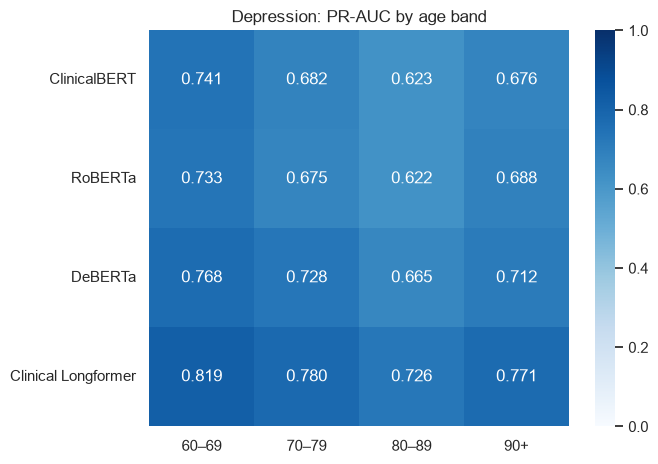

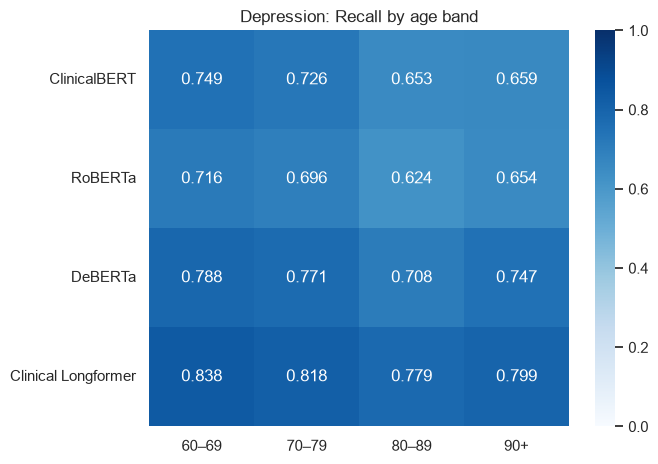

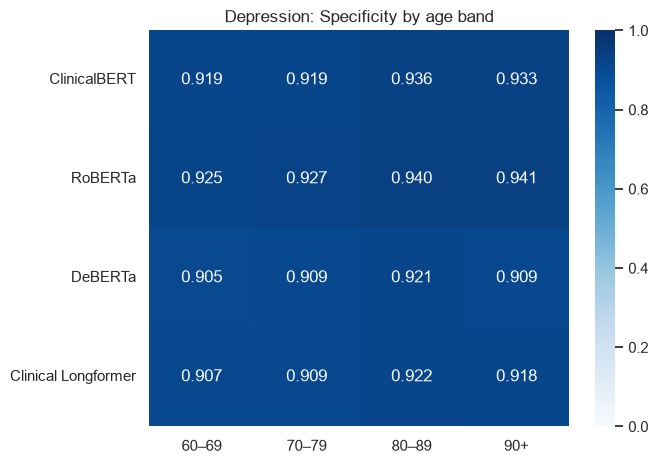

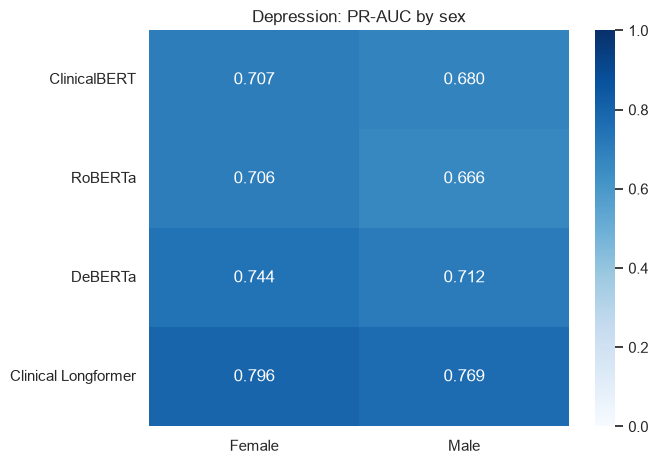

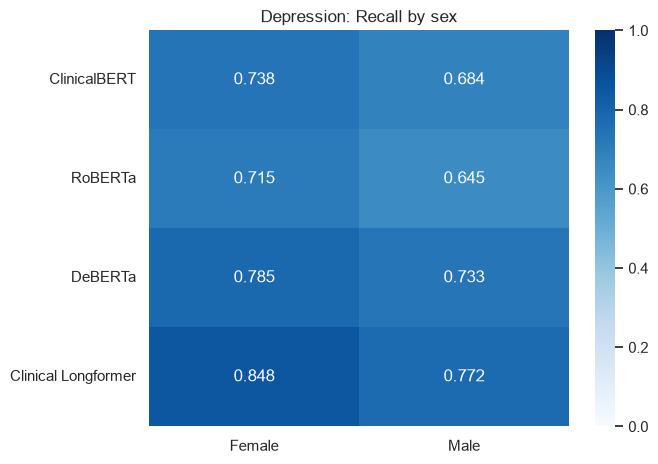

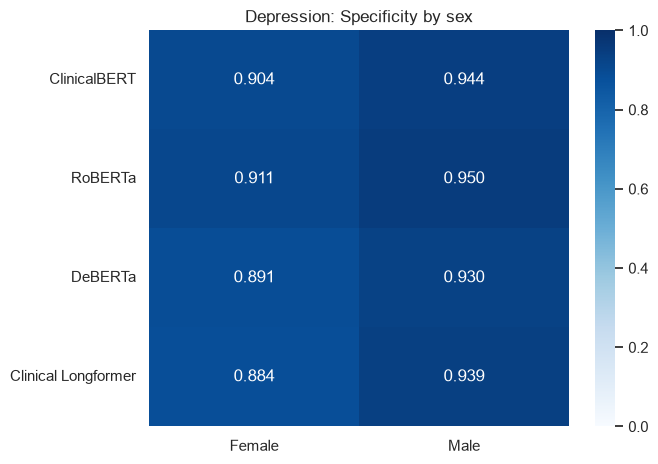

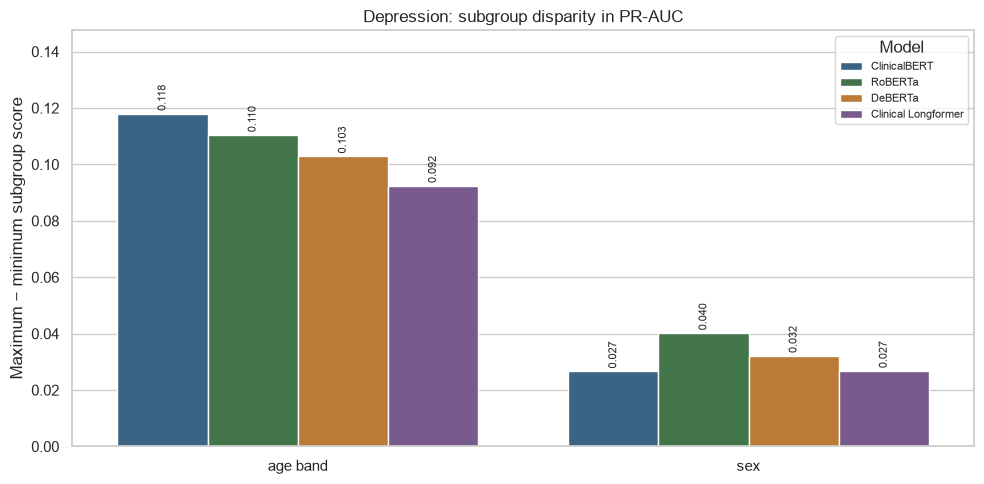

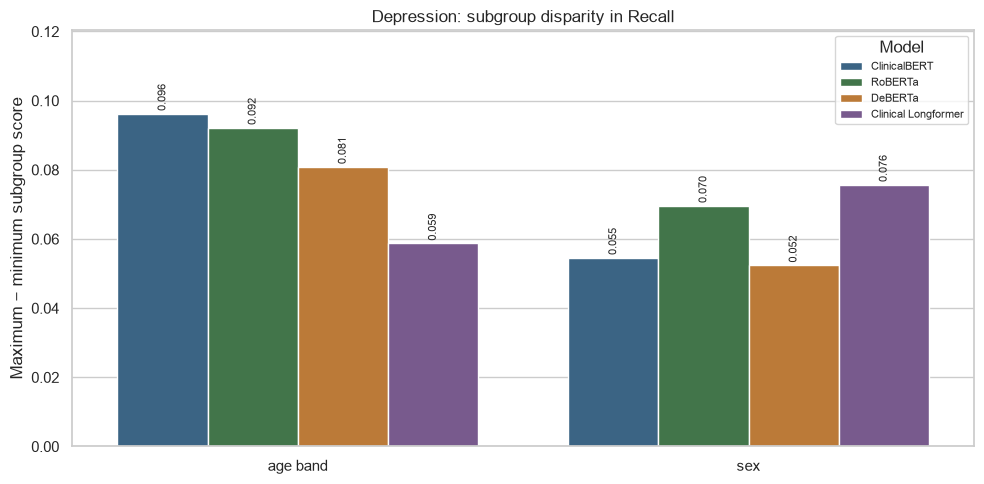

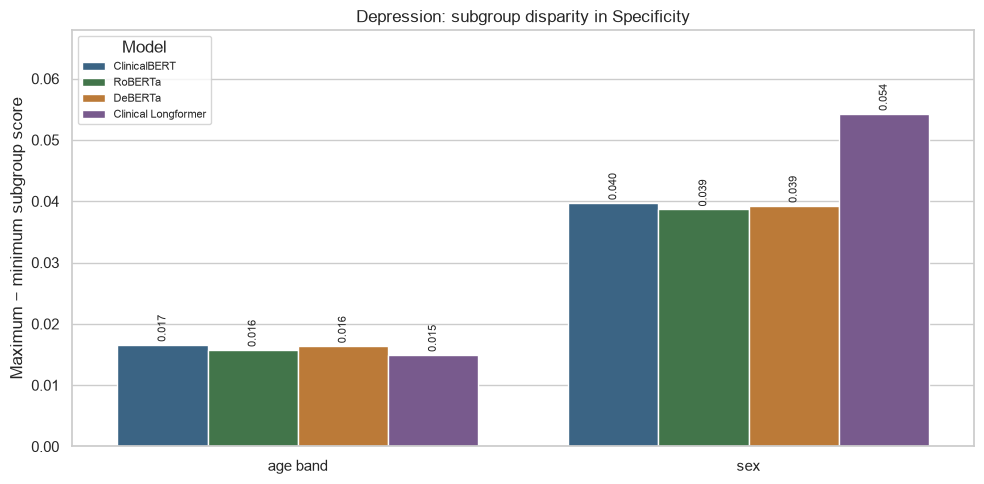

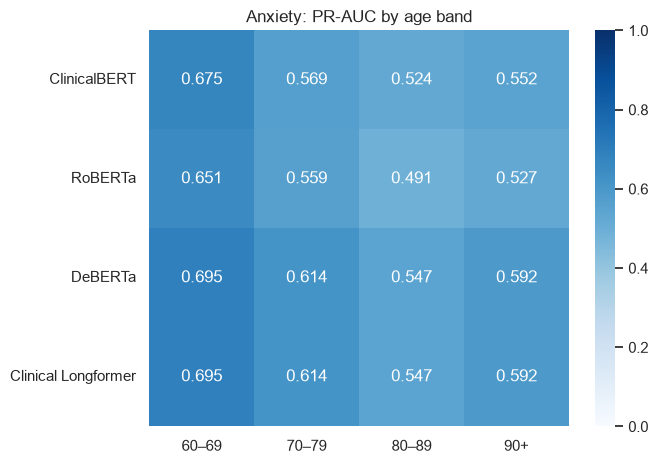

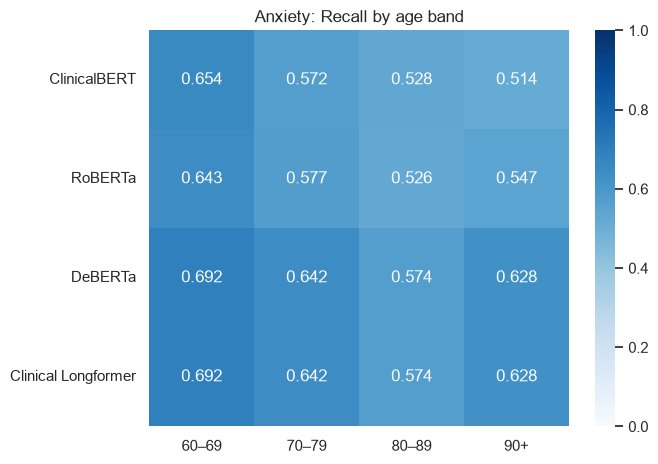

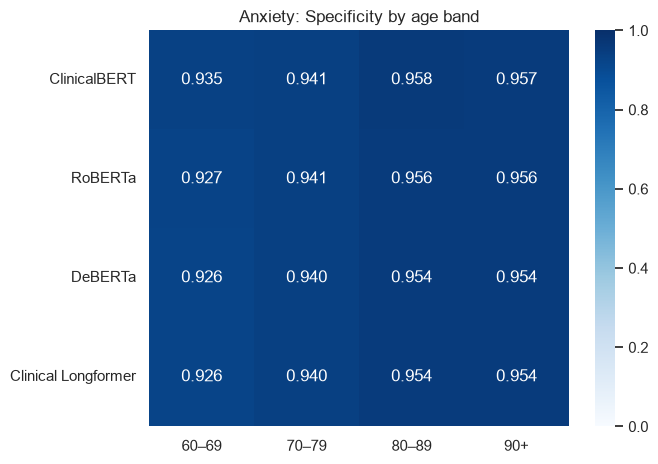

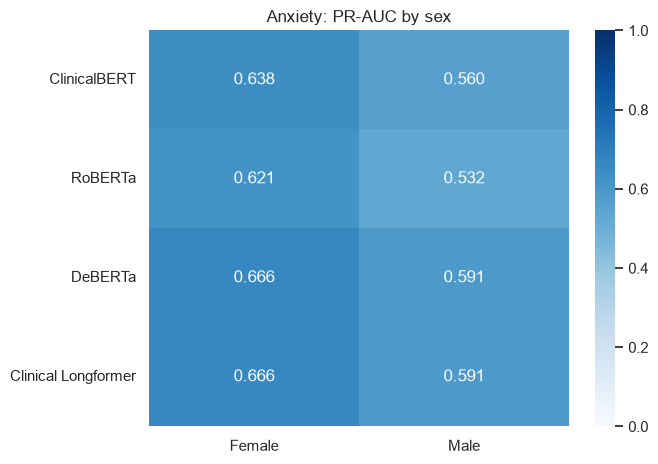

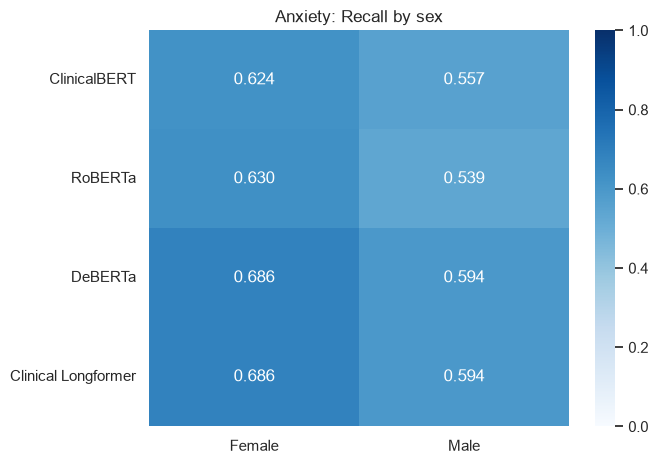

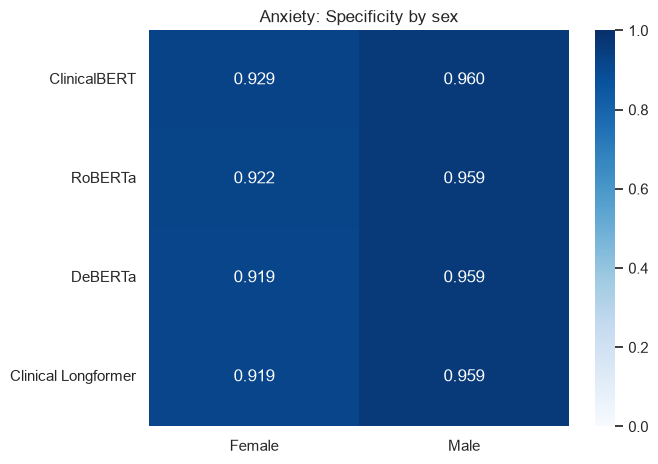

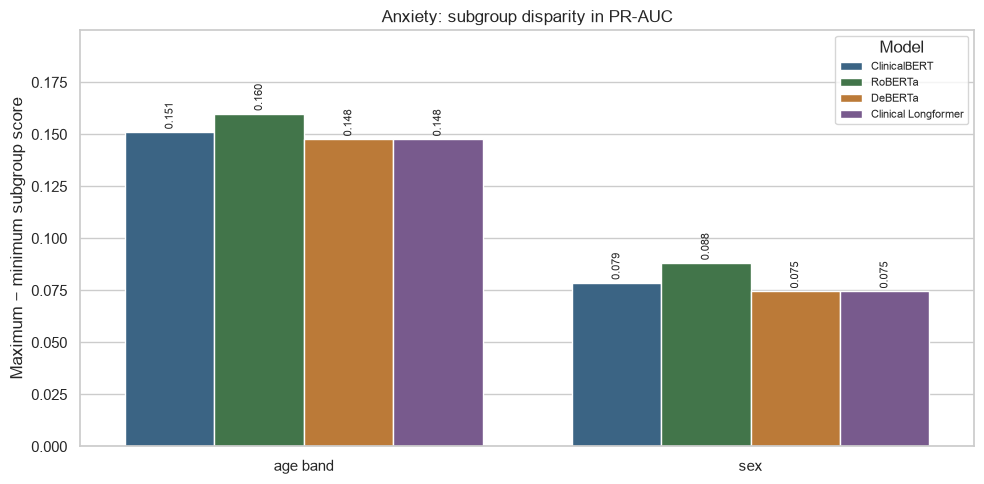

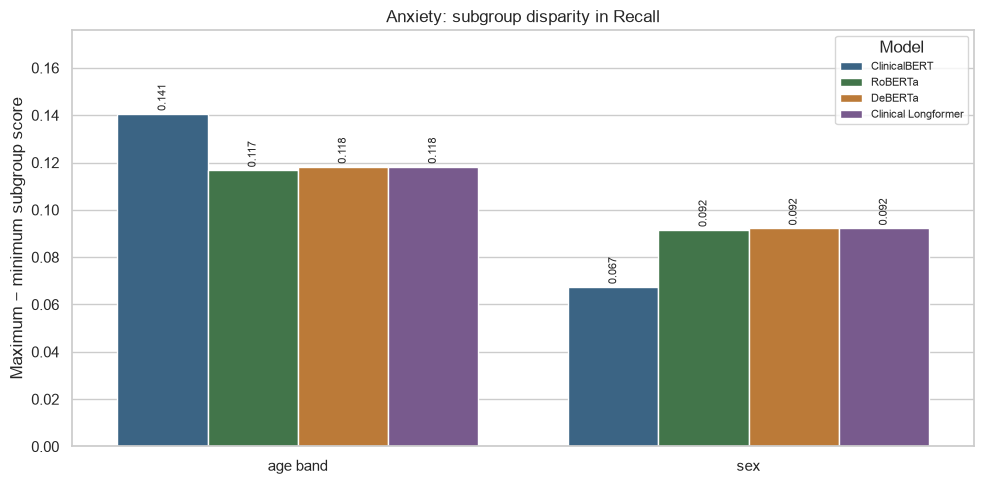

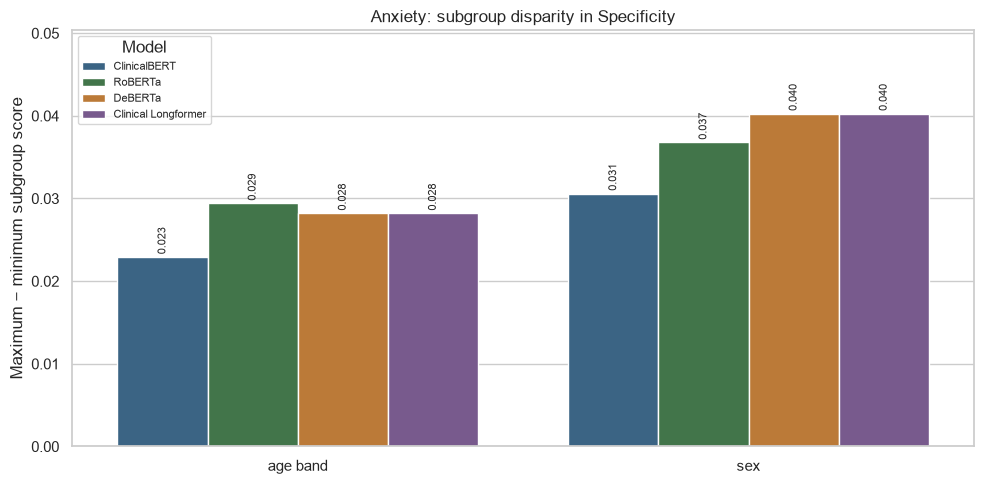

In [18]:
SUBGROUP_LABELS = {"age_band": "age band", "sex_group": "sex", "comorbidity_band": "comorbidity load"}
for task in TASKS:
    subgroup = subgroup_by_task[task]
    if subgroup.empty:
        continue
    for variable in subgroup["subgroup_variable"].unique():
        frame = subgroup[subgroup["subgroup_variable"] == variable]
        for metric in ["pr_auc", "recall", "specificity"]:
            pivot = frame.pivot(index="model", columns="subgroup", values=metric).reindex(MODEL_ORDER)
            figure, axis = plt.subplots(figsize=(max(7, 1.5 * len(pivot.columns)), 4.8))
            sns.heatmap(pivot, annot=True, fmt=".3f", cmap="Blues", vmin=0, vmax=1, ax=axis)
            axis.set(title=f"{task.title()}: {METRIC_LABELS.get(metric, metric)} by {SUBGROUP_LABELS[variable]}",
                     xlabel="", ylabel="")
            axis.tick_params(axis="x", rotation=0)
            axis.tick_params(axis="y", rotation=0)
            figure.tight_layout()
            save_figure(figure, task, f"subgroup_{variable}_{metric}_heatmap")
            plt.show()
            plt.close(figure)

    gaps = subgroup_gap_by_task[task]
    for metric in ["pr_auc", "recall", "specificity"]:
        frame = gaps[gaps["metric"] == metric].copy()
        if frame.empty:
            continue
        frame["subgroup_variable"] = frame["subgroup_variable"].map(SUBGROUP_LABELS)
        figure, axis = plt.subplots(figsize=(10, 5))
        sns.barplot(data=frame, x="subgroup_variable", y="max_minus_min", hue="model",
                    hue_order=MODEL_ORDER, palette=MODEL_COLORS, ax=axis)
        axis.set(title=f"{task.title()}: subgroup disparity in {METRIC_LABELS.get(metric, metric)}",
                 xlabel="", ylabel="Maximum − minimum subgroup score")
        maximum_gap = frame["max_minus_min"].max()
        axis.set_ylim(0, max(0.05, maximum_gap * 1.25))
        label_vertical_bars(axis, decimals=3, fontsize=8, rotation=90)
        axis.legend(title="Model", fontsize=8)
        figure.tight_layout()
        save_figure(figure, task, f"subgroup_disparity_{metric}")
        plt.show()
        plt.close(figure)

## 11. Best-performing model(s) for each task

The point-estimate leader is the model with the highest common-cohort PR-AUC. Other models are marked as statistically distinguishable or not distinguishable from that leader using the Holm-adjusted paired-bootstrap PR-AUC comparison. “Not distinguishable” is not a claim of equivalence or non-inferiority.

In [19]:
ranking_by_task = {}
best_model_summary_by_task = {}
for task in TASKS:
    ranking = common_evaluation_by_task[task].copy()
    ranking["pr_auc_rank"] = ranking["pr_auc"].rank(method="min", ascending=False).astype(int)
    ranking = ranking.sort_values(["pr_auc_rank", "roc_auc", "f1"], ascending=[True, False, False]).reset_index(drop=True)
    leader = ranking.iloc[0]["model"]
    comparisons = bootstrap_comparisons_by_task[task]
    distinguishable = []
    for model in ranking["model"]:
        if model == leader:
            distinguishable.append(False)
            continue
        row = comparisons[(comparisons["metric"] == PRIMARY_METRIC) &
                          (((comparisons["model_a"] == leader) & (comparisons["model_b"] == model)) |
                           ((comparisons["model_a"] == model) & (comparisons["model_b"] == leader)))].iloc[0]
        distinguishable.append(bool(row["significant_after_holm"]))
    ranking["point_estimate_leader"] = ranking["model"].eq(leader)
    ranking["significantly_different_from_leader"] = distinguishable
    ranking["not_distinguishable_from_leader"] = ~ranking["significantly_different_from_leader"]
    ranking_by_task[task] = ranking
    best_model_summary_by_task[task] = ranking[["model", "pr_auc_rank", "pr_auc", "roc_auc", "f1",
                                                "balanced_accuracy", "recall", "specificity", "brier_score",
                                                "point_estimate_leader", "not_distinguishable_from_leader"]]
    ranking.to_csv(TASK_DIRS[task]["tables"] / "model_ranking.csv", index=False)
    best_model_summary_by_task[task].to_csv(TASK_DIRS[task]["tables"] / "best_model_summary.csv", index=False)
    display(Markdown(f"### {task.title()} model ranking"))
    display(best_model_summary_by_task[task].round(4))

### Depression model ranking

,model,pr_auc_rank,pr_auc,roc_auc,f1,balanced_accuracy,recall,specificity,brier_score,point_estimate_leader,not_distinguishable_from_leader
0,Clinical Longformer,1,0.7852,0.9362,0.7298,0.8648,0.8175,0.9121,0.0689,True,True
1,DeBERTa,2,0.7315,0.9134,0.6963,0.8372,0.7639,0.9105,0.0938,False,False
2,ClinicalBERT,3,0.6960,0.8935,0.6889,0.8204,0.7164,0.9245,0.1012,False,False
3,RoBERTa,4,0.6904,0.8869,0.6802,0.8089,0.6869,0.9308,0.0964,False,False


### Anxiety model ranking

,model,pr_auc_rank,pr_auc,roc_auc,f1,balanced_accuracy,recall,specificity,brier_score,point_estimate_leader,not_distinguishable_from_leader
0,DeBERTa,1,0.6400,0.8843,0.6139,0.7966,0.6537,0.9395,0.0832,True,True
1,Clinical Longformer,1,0.6400,0.8843,0.6139,0.7966,0.6537,0.9395,0.0832,False,True
2,ClinicalBERT,3,0.6106,0.8813,0.5895,0.7725,0.6004,0.9445,0.0875,False,False
3,RoBERTa,4,0.5900,0.8614,0.5800,0.7695,0.5979,0.9411,0.0804,False,False


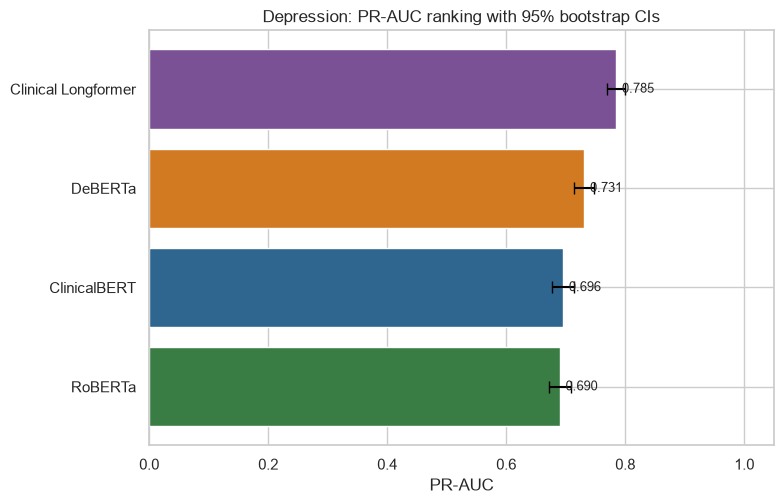

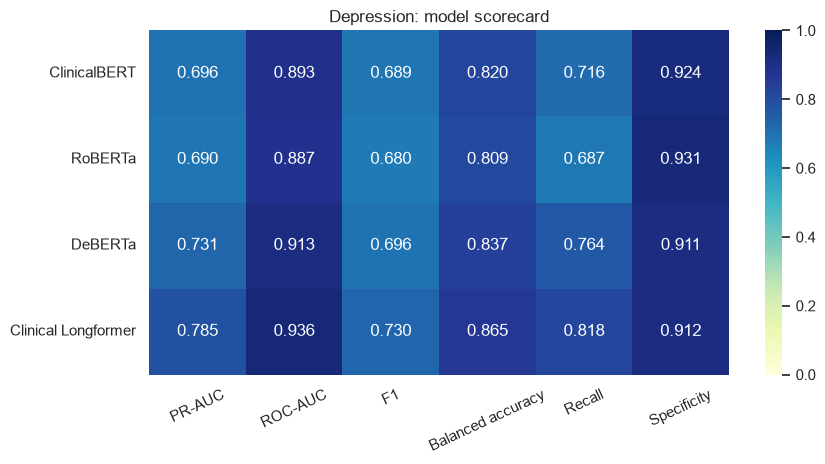

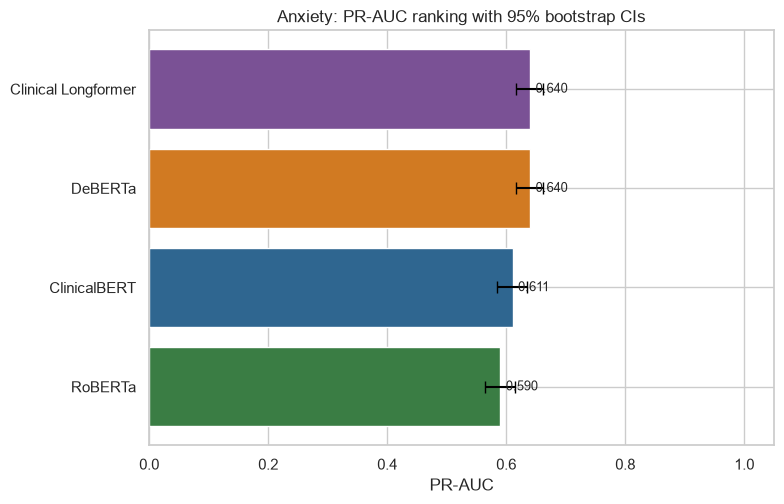

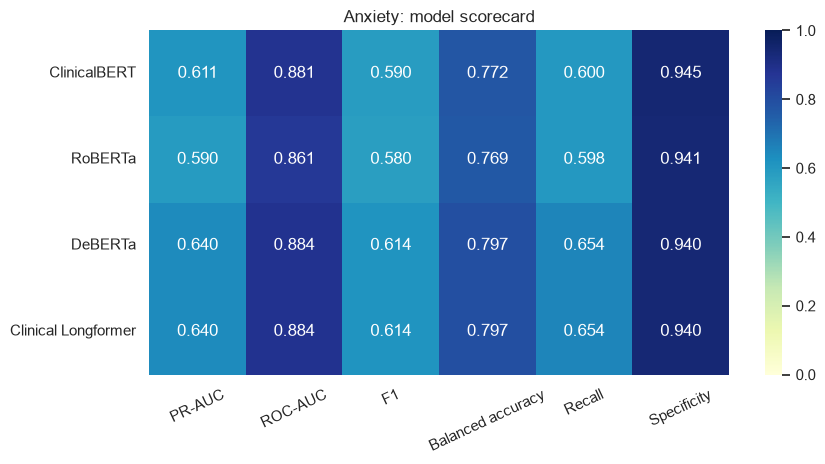

In [20]:
for task in TASKS:
    ci = bootstrap_model_summary_by_task[task]
    pr = ci[ci["metric"] == "pr_auc"].set_index("model").loc[MODEL_ORDER].reset_index()
    pr = pr.sort_values("observed")
    xerr = np.vstack([pr["observed"] - pr["ci_lower"], pr["ci_upper"] - pr["observed"]])
    figure, axis = plt.subplots(figsize=(8, 5.2))
    axis.barh(pr["model"], pr["observed"], color=[MODEL_COLORS[model] for model in pr["model"]])
    axis.errorbar(pr["observed"], pr["model"], xerr=xerr, fmt="none", ecolor="black", capsize=4)
    label_horizontal_bars(axis, decimals=3, fontsize=9)
    axis.set(title=f"{task.title()}: PR-AUC ranking with 95% bootstrap CIs", xlabel="PR-AUC", ylabel="", xlim=(0, 1.05))
    figure.tight_layout()
    save_figure(figure, task, "best_model_pr_auc_ranking")
    plt.show()
    plt.close(figure)

    scorecard = common_evaluation_by_task[task].set_index("model")[PLOT_METRICS].reindex(MODEL_ORDER)
    scorecard = scorecard.rename(columns=METRIC_LABELS)
    figure, axis = plt.subplots(figsize=(9, 4.8))
    sns.heatmap(scorecard, annot=True, fmt=".3f", cmap="YlGnBu", vmin=0, vmax=1, ax=axis)
    axis.set(title=f"{task.title()}: model scorecard", xlabel="", ylabel="")
    axis.tick_params(axis="x", rotation=25)
    axis.tick_params(axis="y", rotation=0)
    figure.tight_layout()
    save_figure(figure, task, "model_scorecard")
    plt.show()
    plt.close(figure)

## 12. Export task reports and dashboard manifests

Each report follows the same structure but contains only one task. This prevents accidental cross-task comparisons and makes the outputs easy to transfer to separate dashboard panels.

In [21]:
def markdown_table(frame, decimals=4):
    try:
        return frame.round(decimals).to_markdown(index=False)
    except ImportError:
        return "```text\n" + frame.round(decimals).to_string(index=False) + "\n```"

def significant_or_message(frame, columns):
    significant = frame[frame["significant_after_holm"]]
    return markdown_table(significant[columns]) if not significant.empty else "No comparison remained significant after Holm correction."

for task in TASKS:
    ranking = ranking_by_task[task]
    leader = ranking.iloc[0]["model"]
    report = [
        f"# {task.title()} Comparative Evaluation", "",
        "## Executive conclusion", "",
        f"The highest common-cohort PR-AUC point estimate was produced by **{leader}**. "
        "Interpret this ranking together with paired confidence intervals, adjusted p-values, calibration and subgroup results.", "",
        "## Cohort audit", "", markdown_table(cohort_audit_by_task[task]), "",
        "## Primary common-cohort test performance", "",
        markdown_table(common_evaluation_by_task[task][["model", "admissions", "patients", "prevalence",
            "accuracy", "balanced_accuracy", "precision", "recall", "specificity", "f1",
            "roc_auc", "pr_auc", "brier_score", "training_hours"]]), "",
        "## Model ranking", "", markdown_table(best_model_summary_by_task[task]), "",
        "## Significant paired-bootstrap comparisons", "",
        significant_or_message(bootstrap_comparisons_by_task[task],
            ["metric", "model_a", "model_b", "observed_difference_a_minus_b", "ci_lower", "ci_upper", "holm_adjusted_p"]), "",
        "## Significant McNemar comparisons", "",
        significant_or_message(mcnemar_by_task[task],
            ["model_a", "model_b", "a_correct_b_wrong", "a_wrong_b_correct", "holm_adjusted_p"]), "",
        "## Subgroup analysis", "",
    ]
    subgroup = subgroup_by_task[task]
    if subgroup.empty:
        report.append("Subgroup results were not produced because configured metadata was unavailable or no group met the minimum size.")
    else:
        report.append(markdown_table(subgroup[["model", "subgroup_variable", "subgroup", "admissions", "patients",
                                               "prevalence", "balanced_accuracy", "recall", "specificity",
                                               "f1", "roc_auc", "pr_auc"]]))
    report += ["", "## Supplementary full-cohort results", "",
               "These model-specific cohorts may differ and are not used for paired significance testing.", "",
               markdown_table(full_evaluation_by_task[task][["model", "admissions", "patients", "accuracy",
                   "balanced_accuracy", "recall", "specificity", "f1", "roc_auc", "pr_auc"]]), "",
               "## Interpretation safeguards", "",
               "- Do not select or retune thresholds using test results.",
               "- Use the common-cohort table for fair model comparison.",
               "- Prefer PR-AUC for the primary ranking because the positive class is imbalanced.",
               "- Interpret statistical significance with effect sizes and confidence intervals.",
               "- Treat small subgroup estimates cautiously; statistical significance does not establish clinical validity."]
    report_path = ANALYSIS_DIR / task / f"{task}_comparative_benchmark_summary.md"
    report_path.write_text("\n".join(report), encoding="utf-8")

    figures = sorted(path.name for path in TASK_DIRS[task]["figures"].glob("*.png"))
    dashboard_manifest = {
        "task": task, "primary_metric": PRIMARY_METRIC, "point_estimate_leader": leader,
        "common_test_admissions": int(common_evaluation_by_task[task].iloc[0]["admissions"]),
        "models": MODEL_ORDER, "figures": figures,
        "primary_table": "tables/common_cohort_test_evaluation.csv",
        "ranking_table": "tables/best_model_summary.csv",
        "subgroup_table": "tables/subgroup_performance.csv",
    }
    manifest_path = TASK_DIRS[task]["dashboard"] / "dashboard_manifest.json"
    manifest_path.write_text(json.dumps(dashboard_manifest, indent=2), encoding="utf-8")
    print(f"Saved {task} report:", report_path)

Saved depression report: /Users/purnaperamune/Documents/GitHub/P000464SE-Modern-Transformer-Models-for-Depression-Anxiety-Detection/model_outputs/comparative_evaluation/depression/depression_comparative_benchmark_summary.md
Saved anxiety report: /Users/purnaperamune/Documents/GitHub/P000464SE-Modern-Transformer-Models-for-Depression-Anxiety-Detection/model_outputs/comparative_evaluation/anxiety/anxiety_comparative_benchmark_summary.md


## 13. Final Week 9 output inventory

The inventory is displayed separately for depression and anxiety. The `dashboard_manifest.json` file identifies the most useful table and figure assets for each dashboard page.

In [22]:
for task in TASKS:
    root = ANALYSIS_DIR / task
    files = sorted(path for path in root.rglob("*") if path.is_file())
    inventory = pd.DataFrame({"file": [str(path.relative_to(root)) for path in files],
                              "size_kb": [round(path.stat().st_size / 1024, 1) for path in files]})
    inventory.to_csv(TASK_DIRS[task]["tables"] / "output_inventory.csv", index=False)
    display(Markdown(f"### {task.title()} output inventory"))
    display(inventory)
print("Week 9 comparative evaluation completed:", ANALYSIS_DIR)

### Depression output inventory

,file,size_kb
0,dashboard/dashboard_manifest.json,1.3
1,depression_comparative_benchmark_summary.md,13.9
2,figures/best_model_pr_auc_ranking.png,70.6
3,figures/best_model_pr_auc_ranking.svg,37.6
4,figures/bootstrap_adjusted_p_value_heatmaps.png,352.2
...,...,...
57,tables/patient_clustered_bootstrap_comparisons...,3.7
58,tables/subgroup_metadata_audit.csv,0.2
59,tables/subgroup_performance.csv,6.8
60,tables/subgroup_performance_gaps.csv,1.7


### Anxiety output inventory

,file,size_kb
0,anxiety_comparative_benchmark_summary.md,12.7
1,dashboard/dashboard_manifest.json,1.3
2,figures/best_model_pr_auc_ranking.png,70.6
3,figures/best_model_pr_auc_ranking.svg,37.0
4,figures/bootstrap_adjusted_p_value_heatmaps.png,352.2
...,...,...
57,tables/patient_clustered_bootstrap_comparisons...,3.3
58,tables/subgroup_metadata_audit.csv,0.2
59,tables/subgroup_performance.csv,6.9
60,tables/subgroup_performance_gaps.csv,1.7


Week 9 comparative evaluation completed: /Users/purnaperamune/Documents/GitHub/P000464SE-Modern-Transformer-Models-for-Depression-Anxiety-Detection/model_outputs/comparative_evaluation
